# Figure: segmentation with the wheel — from video and wheel to syllables

`figure_generation/fig_segmentation` with the wheel added: the same panels, built the same way (`draw_X(fig, spec)`, one 180 mm figure at the end), with
- a new **wheel row** after the paw row: a wheel snippet with its movements time-normalised, where the wheel colours come from, and the median shape of each wheel cluster (3.4's wheel *movement* clusters, `segmentation/wheel_movement_clusters.py`);
- the **channels** panel with the wheel as a fourth channel, the **occupancy** panel with the wheel, and the **donuts** with a fourth ring (wheel state given paw, whisk and lick);
- the trial stacks (old i) and the all-trials composition (old k) left out for now. The pipeline cartoon (b) has a wheel row (`cartoon_segmentation_wheel.py`).

The wheel in the syllable-level panels (channels strip, occupancy, donuts) is the **8-state set** used in the syllables (`K_WHEEL = 8`: still; 'small' = every low-vigor cluster whatever its side, tiny twitches that co-occur with a still paw; left / balanced / right × mid / high); the wheel row shows the 20 clusters it is merged from. Data: the syllables made with `WHEEL_SEGMENTATION = 'movement'`, `WHEEL_BINNING = 'separate'`, whose paw / whisk / lick code is the production one (byte-identical), so every paw panel is unchanged.

| panel | what |
|---|---|
| a, b | cartoons: the task (placeholder) and the segmentation pipeline, now with a wheel row |
| c, d, e | wheel: a snippet of wheel velocity, its movements shaded by cluster, and the same movements time-normalised; where the wheel colours come from; median shape of each cluster |
| f, g, h | paw: a snippet of paw position and its wavelet power; where the paw-state colours come from; power per band per state |
| i | occupancy per trial epoch: wheel, paw, whisking and licking |
| j | wheel, paw, whisking and licking over the states fit to them |
| k | conditional syllable donuts for example sessions (rings, inside out: wheel, paw \| wheel, whisk \| wheel, paw, lick \| wheel, paw, whisk) |
| l | the donut over all trials |

In [1]:
import sys, pathlib, glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import ListedColormap, to_rgb
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'Functions' / 'trial_modes.py').exists() and REPO != REPO.parent:
    REPO = REPO.parent
PI = REPO / 'paper-individuality'
ROOT = str(PI) + '/'
for _d in (PI, PI / 'segmentation', PI / 'figure_generation'):
    sys.path.insert(0, str(_d))
sys.path.insert(0, str(next(PI / d for d in ('vigor/laterality', '4_mice/laterality')
                            if (PI / d / 'laterality_features.py').exists())))
import paper_style as ps
from laterality_features import state_laterality
import wheel_movement_clusters as wmc
ps.use('paper')
ps.use_paw_states('uniform')
plt.rcParams['hatch.linewidth'] = 0.5          # whisking / licking textures

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


## Parameters

In [2]:
FIG = 'fig_segmentation_wheel'
# the syllables with the wheel as its own column (binned_sequence = the production code)
SYLLABLE_FILE = sorted(glob.glob(ROOT + 'data/both_paws+wheelmov-sep_k8-8_own_lick-standard_proficient_8_k_10_bin_syllables_*'))[-1]
WHEEL_STATES_FILES_DIR = ROOT + 'data/states_files_both_paws+wheelmov-sep_k8-8_own_lick-standard/'
STATES_FILES_DIR = ROOT + 'data/states_files/'
TRIALS_DIR = ROOT + 'data/design_matrices/'
EMBEDDING = ROOT + 'clustering/data_files/mouse_LDA_5_bins_raw_shrink0.5_360_28-09-2026'   # only picks the snippet session
EPOCHS = ps.EPOCH_NAMES
FS = 60.0
N_STATES = ps.N_PAW_STATES

# C: wavelet snippet
SNIPPET_FREQS = [0.5, 1.0, 2.0, 4.0, 8.0]
SNIPPET_SECONDS = 8.3
# F: three channels over their states (same session as C)
TRISTRIP_SECONDS = 20.0
TRISTRIP_START = 252          # s; syllable_composition's choice (a window with diverse paw states)
STATE_ALPHA = 0.45
WHISK_COLORS, LICK_COLORS = ['white', '#7F7F7F'], ['white', '#484949']   # only where a texture can't go
# whisking and licking are drawn as TEXTURES, as in the syllables: whisking '/', licking '.' (ps.PAW_HATCH)
WHISK_HATCH, LICK_HATCH = ps.PAW_HATCH[(1, 0)], ps.PAW_HATCH[(0, 1)]
HATCH_INK = '0.2'
WL_BG = '#E4E4E4'                                # light grey under the whisking / licking textures

def hatch_runs(ax, x_edges, on, y0, y1, hatch, ink=HATCH_INK, zorder=1, fc=WL_BG, **kw):
    """Hatch each run of on == 1 (x_edges: len(on) + 1 values) between y0 and y1 on a light grey, no outline."""
    on = np.nan_to_num(np.asarray(on, float)).astype(int)
    cuts = np.r_[0, np.flatnonzero(np.diff(on)) + 1, len(on)]
    for a, b in zip(cuts[:-1], cuts[1:]):
        if on[a] == 1:
            ax.add_patch(Rectangle((x_edges[a], y0), x_edges[b] - x_edges[a], y1 - y0, fc=fc, ec=ink, lw=0,
                                   hatch=hatch, zorder=zorder, **kw))
# wheel row: snippet window length
WHEEL_SNIPPET_SECONDS = 10.0
# K: example sessions
N_EXAMPLES, MAX_MISSING = 4, 0.05
N_EXAMPLE_TRIALS, TRIAL_START = 20, 40
TIME_BEFORE, TIME_AFTER, ALIGN_TO = 1.0, 2.5, 'goCueTrigger_times'
FEEDBACK_COLORS = {1: '#1B7F3B', -1: '#C0392B'}
EVENT_COLORS = {'quiescence start': '#111111', 'stim on': '#060707', 'first movement': '#FCFBFC'}

# the wheel model (20 clusters) and the 8-state set of the syllables
WM = wmc.load_model('proficient', 21)
WD, WK = WM['desc'], WM['K']
WCOL = wmc.colours(WM)[1:]                       # cluster colours; index = cluster
WHATCH = [''] * WK                               # no jitter texture in this figure
WSET_NAMES = wmc.state_names(WM, 'small_side_vigor')   # 'still', 'small' + side x mid / high
STILL_COLOR = '#ECECEC'                           # wheel 'still' (no movement): very light grey, not white
WSET_COLORS = [STILL_COLOR] + wmc.colours(WM, 'small_side_vigor')[1:]
N_WHEEL = len(WSET_NAMES)
# wheel direction, IBL convention (ibllib training_wheel: anti-clockwise = +; trials.choice -1 = CCW turn): the
# 'left' / 'right' states are named by the stimulus side they report, measured on correct trials
# (WM['sign_check']: + velocity on 82 % of right-stimulus vs 18 % of left-stimulus responses), so
# left = clockwise (CW, - velocity, reports a LEFT stimulus) and right = counter-clockwise (CCW, +, reports RIGHT)
assert WM['SIGN_RIGHT'] == 1
DIRECTION = {'left': 'CW', 'both': 'Balanced', 'right': 'CCW'}
WSET_LABELS = [' '.join(DIRECTION.get(w, w) if w != 'both' else 'both' for w in n.split()) for n in WSET_NAMES]
WHEEL_VEL_LABEL = 'Wheel\n(rad/s, CCW +)'
# every cluster drawn in the colour of the merged state it belongs to (the 8-state set used everywhere else)
WSTATE_OF = wmc.state_map(WM, 'small_side_vigor')                # cluster -> state number (1..)
WCOL_STATE = [WSET_COLORS[WSTATE_OF[c]] for c in range(WK)]

## Data

In [3]:
seq = pd.read_parquet(SYLLABLE_FILE)
seq['binned_sequence'] = seq['binned_sequence'].apply(ps.paw_codes)     # -> uniform (vigor) numbering
seq['session'] = seq['sample'].str[:36]
emb = pd.read_pickle(EMBEDDING)

def codes_for(rows, col='binned_sequence'):
    piv = rows.pivot(index=['sample'], columns=['broader_label'], values=col).dropna()
    return np.vstack(piv[EPOCHS].apply(lambda r: np.hstack(r), axis=1)).astype(float)

ALL_CODES = codes_for(seq)
ALL_WHEEL = codes_for(seq, 'wheel_binned_sequence')
_wheel_all = np.vstack(seq['wheel_binned_sequence'].to_numpy()).astype(float)
_arr = np.vstack(seq['binned_sequence'].to_numpy())
_paw_all, _whisk_all, _lick_all = ps.decode_syllables(_arr, N_STATES)
_session, _epoch = seq['session'].to_numpy(), seq['broader_label'].to_numpy()
print(f"{seq['session'].nunique()} sessions, {seq['mouse_name'].nunique()} mice, {len(ALL_CODES):,} trials")

332 sessions, 101 mice, 206,879 trials


## Panels A and B — space for the cartoons

In [4]:
def draw_placeholder(fig, spec, text):
    ax = fig.add_subplot(spec)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(True); s.set_color('0.75'); s.set_linestyle((0, (3, 3))); s.set_linewidth(0.6)
    ax.text(0.5, 0.5, text, ha='center', va='center', color='0.6', transform=ax.transAxes)
    return [ax]

draw_A = lambda fig, spec: draw_placeholder(fig, spec, 'Task and video view\n(cartoon)')
import cartoon_segmentation_wheel   # mock signals; figure_generation/cartoon_segmentation_wheel.py (the paw cartoon + a wheel row)
draw_B = cartoon_segmentation_wheel.draw

## Panel C — a snippet of paw position and its wavelet power

The most active 8.3 s window of the first session with both paw wavelets and an LDA embedding (as in `syllable_composition`). Top: horizontal paw position (z-scored; the left camera's x halved for its 2× resolution); bottom: wavelet power at 0.5–8 Hz, tints of each paw's colour (violet = left, amber = right).

CSH_ZAD_029 064a7252, window 1502-1511 s


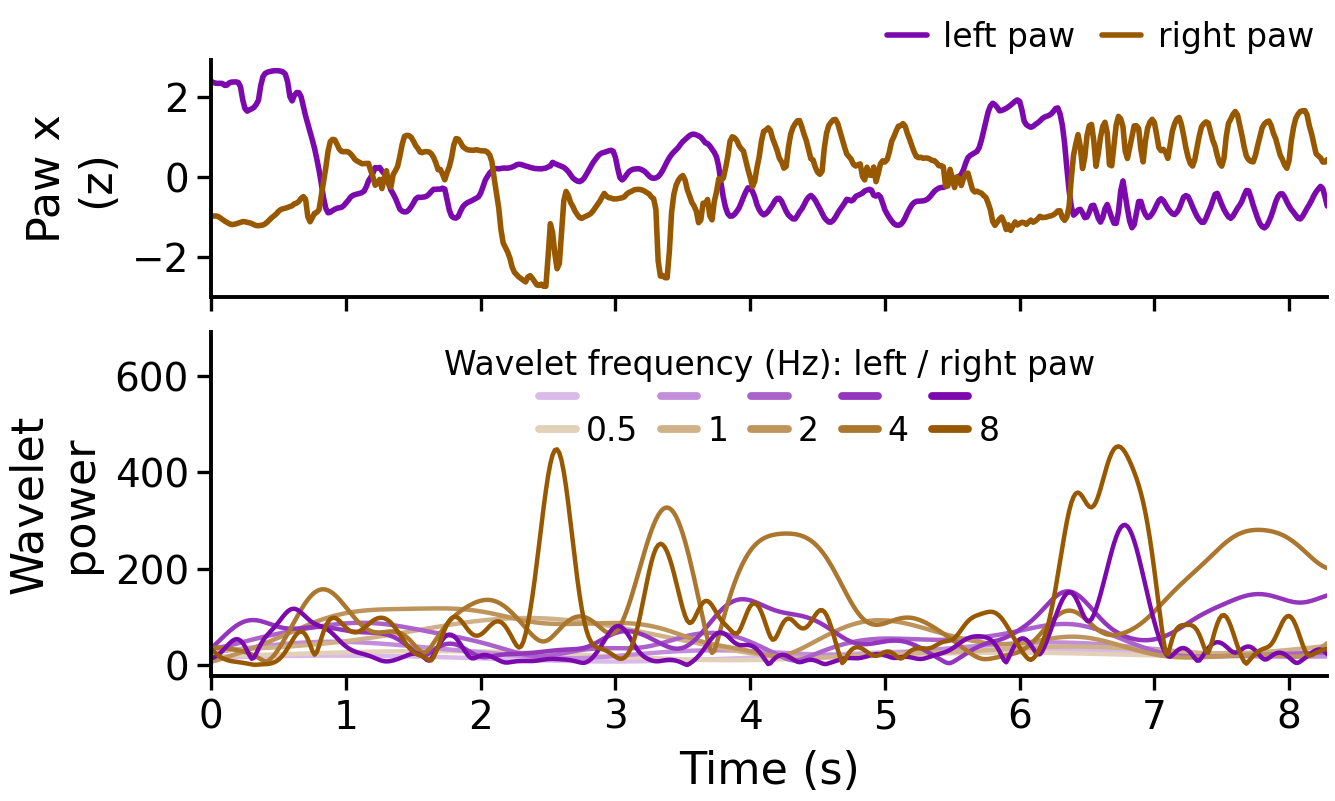

In [5]:
_wav = {os.path.basename(f).split('_')[3]: f for f in glob.glob(ROOT + 'data/paw_wavelets/*/paw_vel_wavelets_*')}
SNIP_SESSION = sorted(set(_wav) & set(emb['session']))[0]
SNIP_MOUSE = emb.loc[emb['session'] == SNIP_SESSION, 'mouse_name'].iloc[0]
_cols = ['l_paw_x', 'r_paw_x'] + [f'{p}_paw_x{f}' for p in ('l', 'r') for f in SNIPPET_FREQS]
_D = pd.read_parquet(_wav[SNIP_SESSION])[_cols].dropna().to_numpy()
_w = int(SNIPPET_SECONDS * FS)
_act = [np.nanstd(_D[i:i + _w, 0]) + np.nanstd(_D[i:i + _w, 1]) for i in range(0, len(_D) - _w, _w)]
_s0 = int(np.argmax(_act)) * _w
SNIP = _D[_s0:_s0 + _w]
print(f'{SNIP_MOUSE} {SNIP_SESSION[:8]}, window {_s0 / FS:.0f}-{(_s0 + _w) / FS:.0f} s')

def freq_ramp(hexcol, n, lightest=0.72):
    base = np.array(to_rgb(hexcol))
    return [tuple(base * (1 - f) + f) for f in np.linspace(lightest, 0.0, n)]

def draw_C(fig, spec, legend=True):
    g = spec.subgridspec(2, 1, height_ratios=[1, 1.45], hspace=0.12)
    axp = fig.add_subplot(g[0]); axw = fig.add_subplot(g[1], sharex=axp)
    t = np.arange(len(SNIP)) / FS
    z = lambda v: (v - v.mean()) / v.std()
    axp.plot(t, z(SNIP[:, 0] / 2), color=ps.PAW_LEFT, lw=1.0, label='left paw')
    axp.plot(t, z(SNIP[:, 1]), color=ps.PAW_RIGHT, lw=1.0, label='right paw')
    axp.set_ylabel('Paw x\n(z)')
    axp.tick_params(labelbottom=False)
    nf = len(SNIPPET_FREQS)
    Lr, Rr = freq_ramp(ps.PAW_LEFT, nf), freq_ramp(ps.PAW_RIGHT, nf)
    for i in range(nf):
        axw.plot(t, SNIP[:, 2 + i], color=Lr[i], lw=0.8)
        axw.plot(t, SNIP[:, 2 + nf + i], color=Rr[i], lw=0.8)
    axw.set_ylabel('Wavelet\npower'); axw.set_xlabel('Time (s)'); axw.set_xlim(t[0], t[-1])
    if legend:
        fs = plt.rcParams['legend.fontsize'] * 0.85
        axp.legend(frameon=False, ncol=2, loc='lower right', bbox_to_anchor=(1, 0.97), borderaxespad=0,
                   fontsize=fs, handlelength=1.2, columnspacing=0.8)
        # frequency key: the tint ladder of each paw, light = slow, dark = fast; headroom so it clears the traces
        axw.set_ylim(top=axw.get_ylim()[1] * 1.45)
        # legends fill column by column: each column is one frequency, left-paw tint over right-paw tint
        hs, ls = [], []
        for i, f in enumerate(SNIPPET_FREQS):
            hs += [Line2D([], [], color=Lr[i], lw=1.4), Line2D([], [], color=Rr[i], lw=1.4)]
            ls += ['', f'{f:g}']
        axw.legend(handles=hs, labels=ls, ncol=nf, frameon=False, loc='upper center',
                   title='Wavelet frequency (Hz): left / right paw', fontsize=fs, title_fontsize=fs,
                   handlelength=1.1, columnspacing=0.7, labelspacing=0.0, handletextpad=0.3, borderaxespad=0.1)
    return [axp, axw]

fig = plt.figure(figsize=(3.6, 2.0)); draw_C(fig, fig.add_gridspec(1, 1)[0]); plt.show()

## Panel D — where the paw-state colours come from

Per state (vigor order): **vigor** = mean z-scored 0.5–8 Hz power over both paws (sets lightness), and the **left − right gap** (sets hue and chroma: violet = left-led, amber = right-led). Recomputed from the state wavelet profiles (`laterality_features.state_laterality`).

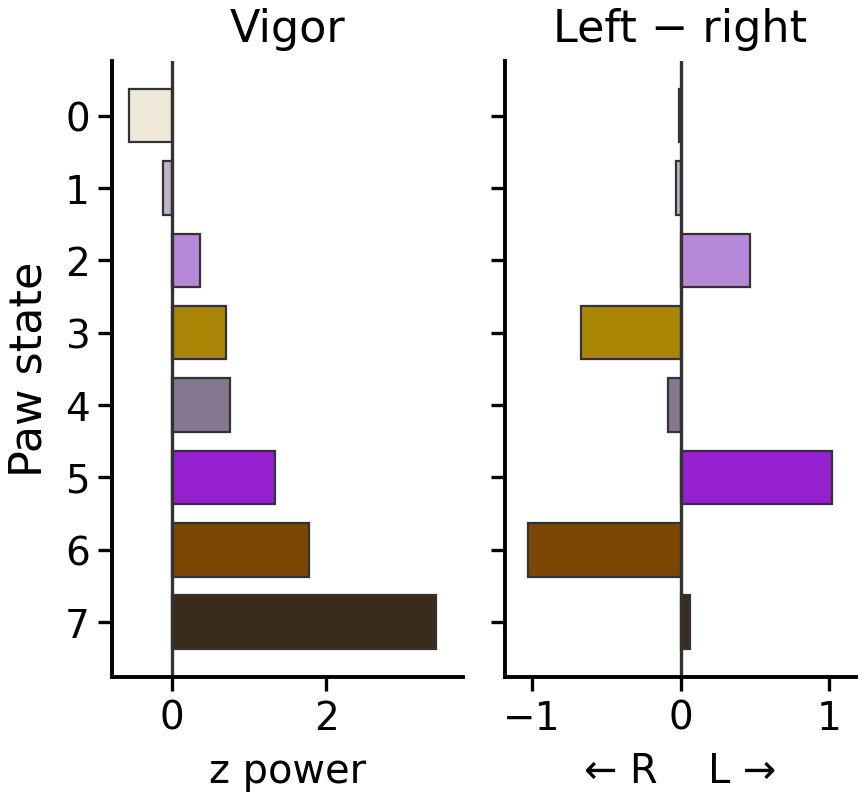

In [6]:
S = state_laterality(ps.paw_profiles(ROOT))
S['gap'] = S['left'] - S['right']
ORDER = list(ps.PAW_VIGOR_ORDER)

def draw_D(fig, spec):
    g = spec.subgridspec(1, 2, wspace=0.12)
    ypos = -np.arange(len(ORDER))
    axes = []
    for j, (col, title) in enumerate([('overall', 'Vigor'), ('gap', 'Left − right')]):
        ax = fig.add_subplot(g[j], sharey=axes[0] if axes else None); axes.append(ax)
        vals = np.array([S[col][s] for s in ORDER])
        ax.barh(ypos, vals, height=0.74, color=[ps.PAW_STATE_COLORS[s] for s in ORDER], edgecolor='#333333', lw=0.4)
        ax.axvline(0, color='#333333', lw=0.6)
        ax.set_title(title, fontsize=plt.rcParams['font.size'])
        if col == 'overall':
            ax.set_xlim(vals.min() * 1.4, vals.max() * 1.1)
        else:
            m = np.abs(vals).max() * 1.15
            ax.set_xlim(-m, m)
        ax.set_xticks([0, 2] if col == 'overall' else [-1, 0, 1])
    axes[0].set_yticks(ypos); axes[0].set_yticklabels([str(s) for s in ORDER])
    axes[0].set_ylabel('Paw state')
    axes[1].tick_params(labelleft=False)
    axes[0].set_xlabel('z power', fontsize=plt.rcParams['font.size'] * 0.9)
    axes[1].set_xlabel('← R    L →', fontsize=plt.rcParams['font.size'] * 0.9)
    return axes

fig = plt.figure(figsize=(2.4, 2.0)); draw_D(fig, fig.add_gridspec(1, 1)[0]); plt.show()

## Panel E — power per wavelet band, each paw and state

Mean z-scored power per band (x and y averaged), one line per state, one panel per paw, on one y scale.

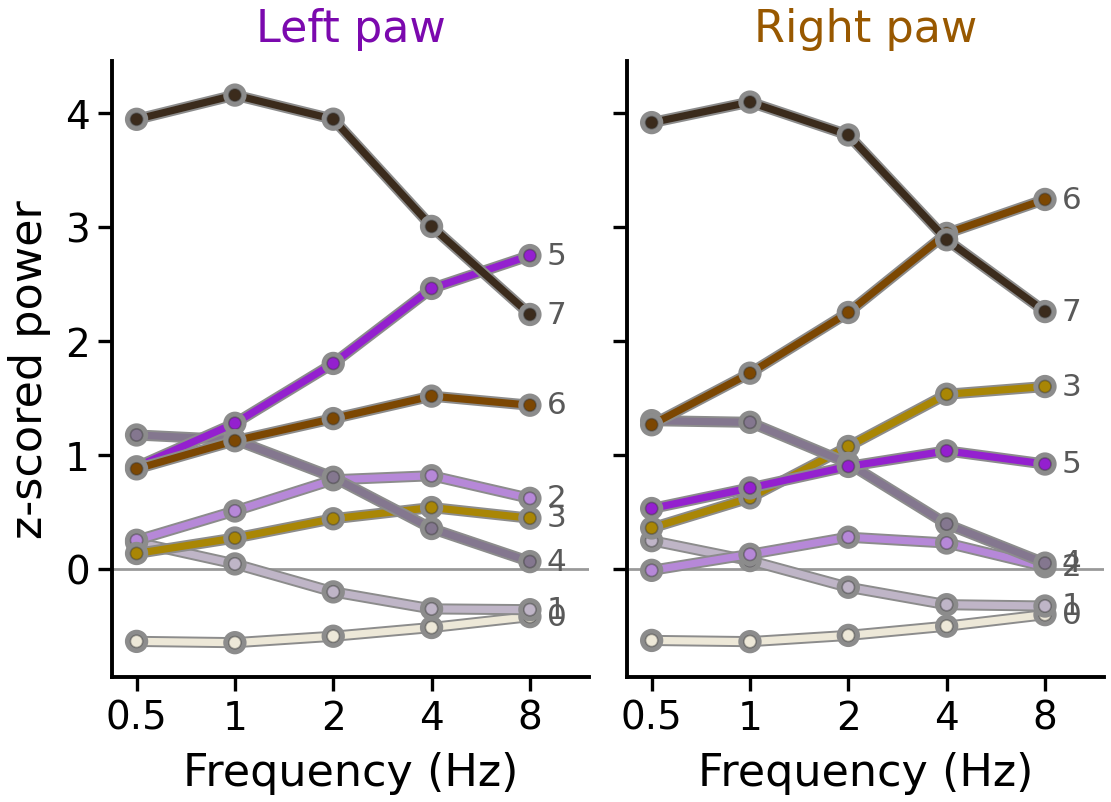

In [7]:
_prof = ps.paw_profiles(ROOT)
FREQS = [0.5, 1.0, 2.0, 4.0, 8.0]
SPECTRUM = {p: pd.DataFrame({f: _prof[[f'{p}_paw_x{f}', f'{p}_paw_y{f}']].mean(axis=1) for f in FREQS}) for p in ('l', 'r')}

def draw_E(fig, spec):
    g = spec.subgridspec(1, 2, wspace=0.08)
    lo = min(SPECTRUM['l'].values.min(), SPECTRUM['r'].values.min())
    hi = max(SPECTRUM['l'].values.max(), SPECTRUM['r'].values.max())
    x = np.arange(len(FREQS))
    axes = []
    for j, (p, name, accent) in enumerate([('l', 'Left paw', ps.PAW_LEFT), ('r', 'Right paw', ps.PAW_RIGHT)]):
        ax = fig.add_subplot(g[j], sharey=axes[0] if axes else None); axes.append(ax)
        ax.axhline(0, color='#999999', lw=0.5)
        for s in ORDER:
            y = SPECTRUM[p].loc[s].to_numpy()
            ax.plot(x, y, color=ps.PAW_STATE_COLORS[s], lw=1.3, marker='o', ms=2.2,
                    mec='#33333366', mew=0.3, path_effects=[pe.Stroke(linewidth=2.0, foreground='0.55'), pe.Normal()])
            ax.annotate(str(s), (x[-1], y[-1]), xytext=(3, 0), textcoords='offset points', va='center',
                        fontsize=plt.rcParams['font.size'] * 0.7, color='0.35')
        ax.set_xticks(x); ax.set_xticklabels([f'{f:g}' for f in FREQS])
        ax.set_xlim(-0.25, len(FREQS) - 0.4); ax.set_ylim(lo - 0.3, hi + 0.3)
        ax.set_xlabel('Frequency (Hz)')
        ax.set_title(name, fontsize=plt.rcParams['font.size'], color=accent)
    axes[0].set_ylabel('z-scored power')
    axes[1].tick_params(labelleft=False)
    return axes

fig = plt.figure(figsize=(3.2, 2.0)); draw_E(fig, fig.add_gridspec(1, 1)[0]); plt.show()

## Wheel row — snippet, colours, cluster shapes

Same session as the paw snippet (c), its most diverse `WHEEL_SNIPPET_SECONDS` window (the one holding the most distinct clusters). Every IBL wheel movement (±50 ms) is shaded by its cluster (number above); below, the same movements as they are clustered (signed velocity in rad/s, each stretched to 200 bins), overlaid on one 0–1 axis per side group: left, balanced, right. No jitter texture in this figure. Colours: hue = the stimulus side the movement reports (teal left, orange right, grey balanced), lightness = vigor.

CSH_ZAD_029 064a7252: wheel window 3578-3588 s


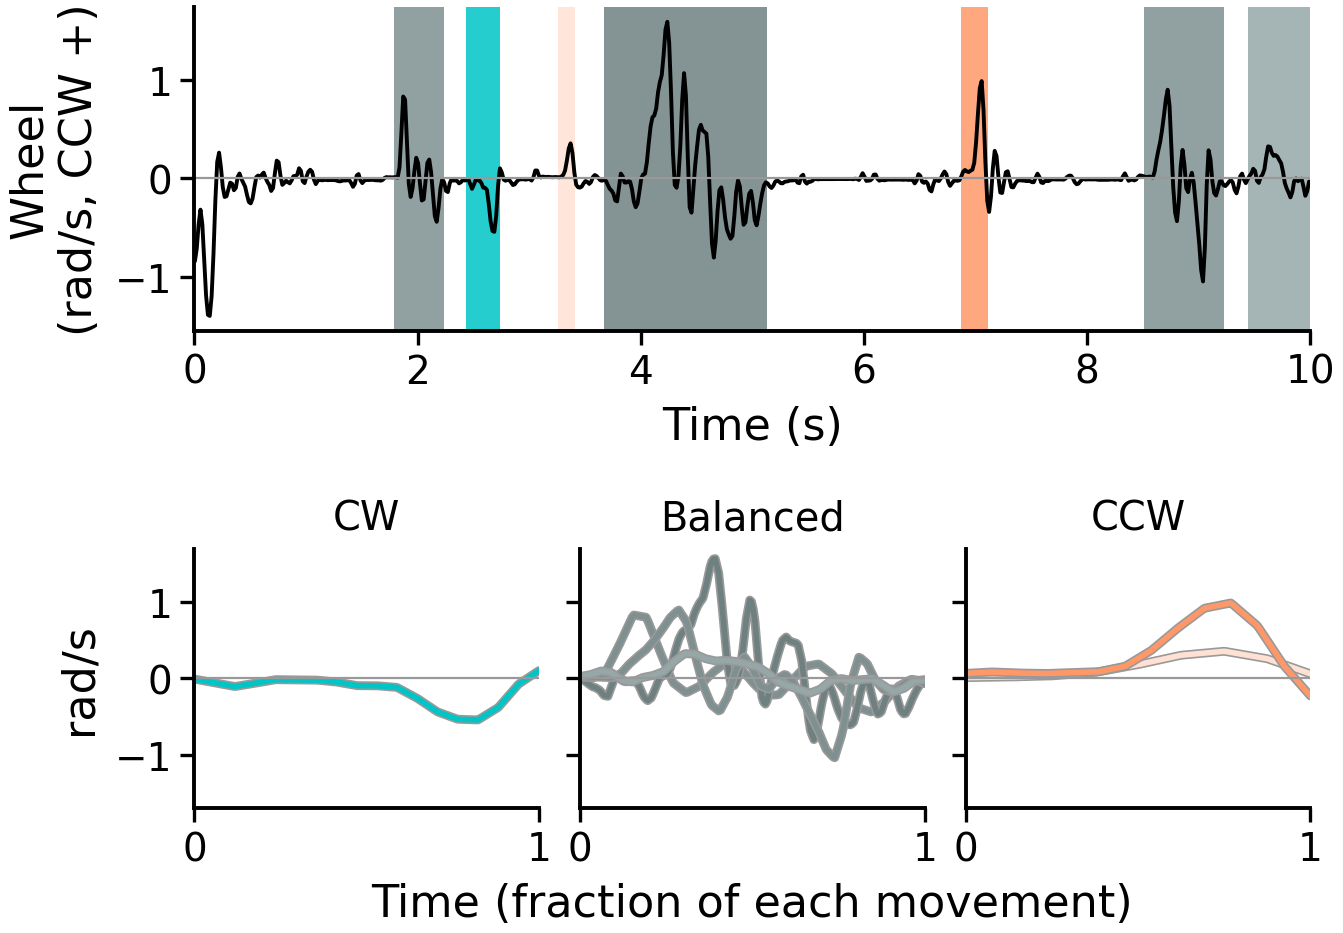

In [8]:
_wt, _wv, _wiv, _ = wmc.load_session('proficient', SNIP_MOUSE, SNIP_SESSION)
WS, WI = wmc.shapes(_wt, _wv, _wiv)
WI['cluster'] = wmc.predict(WM, WS, WI.duration)
def _diversity(t0):
    q = WI[(WI.onset >= t0) & (WI.offset <= t0 + WHEEL_SNIPPET_SECONDS)]
    return q.cluster.nunique() + 0.01 * len(q)
_starts = np.arange(WI.onset.min(), WI.onset.max() - WHEEL_SNIPPET_SECONDS, WHEEL_SNIPPET_SECONDS / 2)
WSNIP_T0 = _starts[int(np.argmax([_diversity(s) for s in _starts]))]
print(f'{SNIP_MOUSE} {SNIP_SESSION[:8]}: wheel window {WSNIP_T0:.0f}-{WSNIP_T0 + WHEEL_SNIPPET_SECONDS:.0f} s')

def draw_W1(fig, spec):
    """Top: the wheel trace with every movement shaded by its cluster. Below: the same movements as they are
    clustered (signed velocity, each stretched to 200 bins), overlaid on one 0-1 axis per side group."""
    g = spec.subgridspec(2, 1, height_ratios=[1.25, 1], hspace=0.75)
    ax = fig.add_subplot(g[0])
    sel = (_wt >= WSNIP_T0) & (_wt < WSNIP_T0 + WHEEL_SNIPPET_SECONDS)
    q = WI[(WI.onset >= WSNIP_T0) & (WI.offset <= WSNIP_T0 + WHEEL_SNIPPET_SECONDS)]
    fs = plt.rcParams['font.size'] * 0.75
    for _, r in q.iterrows():
        c = int(r.cluster)
        ax.axvspan(r.onset - wmc.PAD_S - WSNIP_T0, r.offset + wmc.PAD_S - WSNIP_T0, facecolor=WCOL[c], lw=0, alpha=0.85)
    ax.plot(_wt[sel] - WSNIP_T0, _wv[sel], color='k', lw=0.7)
    ax.axhline(0, color='0.6', lw=0.4)
    ax.set(xlim=(0, WHEEL_SNIPPET_SECONDS), ylabel=WHEEL_VEL_LABEL, xlabel='Time (s)')
    gs = g[1].subgridspec(1, 3, wspace=0.12)
    x = np.linspace(0, 1, wmc.NT)
    lim = np.abs(WS[q.index]).max() * 1.08 if len(q) else 1
    axes = [ax]
    for j, side in enumerate(wmc.SIDES):
        a_ = fig.add_subplot(gs[j], sharey=axes[1] if j else None); axes.append(a_)
        for k, r in q.iterrows():
            c = int(r.cluster)
            if WD.side[c] == side:
                a_.plot(x, WS[k], color=WCOL[c], lw=1.0, path_effects=[pe.Stroke(linewidth=1.6, foreground='0.6'), pe.Normal()])
        a_.axhline(0, color='0.6', lw=0.4)
        a_.set(xlim=(0, 1), xticks=[0, 1], ylim=(-lim, lim))
        a_.set_title(DIRECTION[side], fontsize=plt.rcParams['font.size'] * 0.9)
        if j: a_.tick_params(labelleft=False)
    axes[1].set_ylabel('rad/s'); axes[2].set_xlabel('Time (fraction of each movement)')
    return axes

fig = plt.figure(figsize=(3.6, 2.6)); draw_W1(fig, fig.add_gridspec(1, 1)[0]); plt.show()

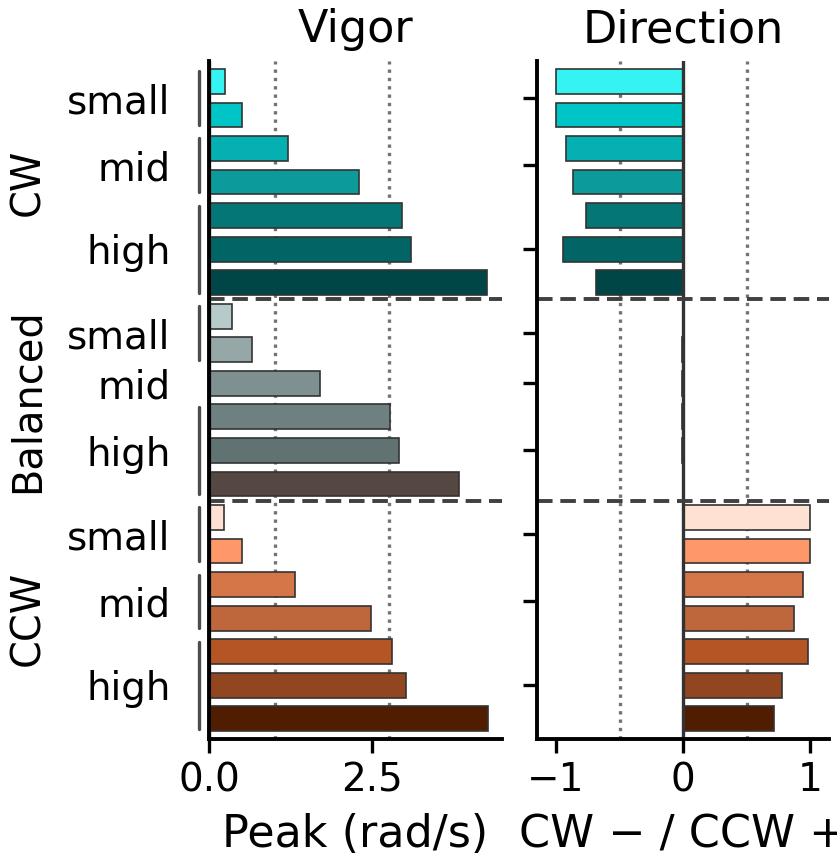

In [9]:
def draw_W2(fig, spec):
    """The 20 clusters, one bar each, in its own colour; brackets + labels = the merged state it belongs to. Dashed lines: the
    direction groups (each fitted with its own GMM). Dotted lines: the cuts that define the merge (median peak
    1 / 2.75 rad/s -> small / mid / high) and the split (travel balance +-0.5, applied per movement)."""
    g = spec.subgridspec(1, 2, wspace=0.12)
    y = -np.arange(WK)
    groups = [np.flatnonzero(WD.side.values == s_) for s_ in wmc.SIDES]
    axes = []
    for j, (vals, title, xl, lim, cuts) in enumerate([
            (WD.peak_rad_s.values, 'Vigor', 'Peak (rad/s)', None, wmc.VIGOR_CUTS),
            (WD.side_index.values, 'Direction', 'CW − / CCW +', (-1.15, 1.15), (-WM['SPLIT'], WM['SPLIT']))]):
        ax = fig.add_subplot(g[j], sharey=axes[0] if axes else None); axes.append(ax)
        ax.barh(y, vals, height=0.74, color=WCOL, edgecolor='#333333', lw=0.3)
        ax.axvline(0, color='#333333', lw=0.6)
        for c_ in cuts:
            ax.axvline(c_, color='0.45', lw=0.6, ls=(0, (1, 1.5)), zorder=0)
        for grp in groups[:-1]:
            ax.axhline(-grp.max() - 0.5, color='0.25', lw=0.7, ls=(0, (4, 2)), clip_on=False)
        ax.set_title(title, fontsize=plt.rcParams['font.size']); ax.set_xlabel(xl)
        if lim: ax.set_xlim(*lim)
    ax0 = axes[0]
    ax0.set_ylim(-WK + 0.4, 0.6)
    # one tick per merged state (its run of clusters), direction written outside
    names = np.array(wmc.group_of(WM, 'small_side_vigor'))
    ticks, labels = [], []
    for grp in groups:
        cuts_ = np.r_[0, np.flatnonzero(names[grp][1:] != names[grp][:-1]) + 1, len(grp)]
        for a, b in zip(cuts_[:-1], cuts_[1:]):
            ticks.append(-(grp[a] + grp[b - 1]) / 2)
            labels.append(names[grp[a]].split()[-1])
            if b - a > 1:                          # bracket the clusters merged into this state
                ax0.plot([-0.035, -0.035], [-grp[a] + 0.3, -grp[b - 1] - 0.3], color='0.3', lw=0.6,
                         transform=ax0.get_yaxis_transform(), clip_on=False)
    ax0.set_yticks(ticks); ax0.set_yticklabels(labels)
    ax0.tick_params(axis='y', length=0, pad=7)
    for side, grp in zip(wmc.SIDES, groups):
        ax0.text(-0.62, -grp.mean(), DIRECTION[side], transform=ax0.get_yaxis_transform(), rotation=90,
                 ha='center', va='center', fontsize=plt.rcParams['font.size'] * 0.9)
    axes[1].tick_params(labelleft=False)
    return axes

fig = plt.figure(figsize=(2.0, 2.2)); draw_W2(fig, fig.add_gridspec(1, 1)[0]); plt.show()

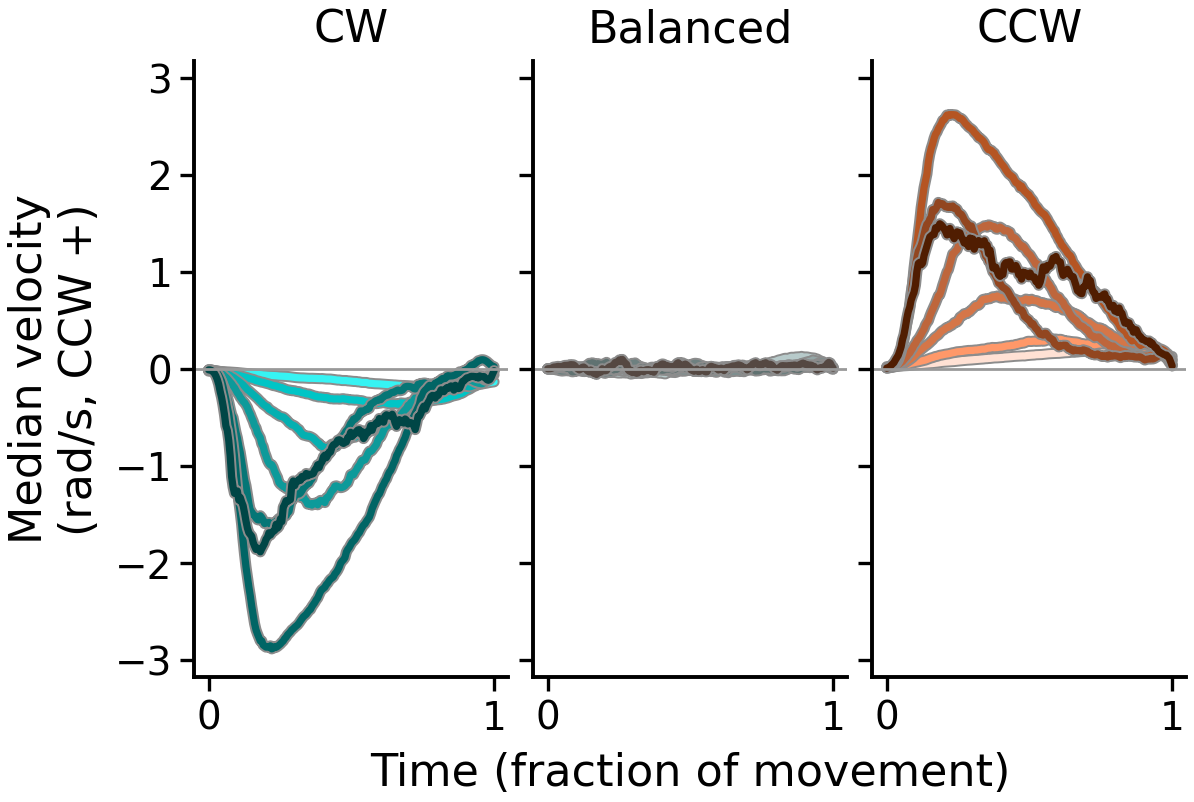

In [10]:
def _cluster_medians(n_per_session=60, seed=0):
    from joblib import Parallel, delayed
    rng = np.random.default_rng(seed)
    coh = wmc.fit_cohort()
    def one(m, e):
        S, info = wmc.shapes(*wmc.load_session('proficient', m, e)[:3])
        idx = rng.choice(len(S), min(n_per_session, len(S)), replace=False)
        return S[idx], wmc.predict(WM, S[idx], info.duration.values[idx])
    out = Parallel(n_jobs=10)(delayed(one)(m, e) for m, e in zip(coh.mouse, coh.eid))
    S = np.concatenate([o[0] for o in out]); c = np.concatenate([o[1] for o in out])
    return np.array([np.median(S[c == k], 0) for k in range(WK)])
WMED = _cluster_medians()

def draw_W3(fig, spec):
    g = spec.subgridspec(1, 3, wspace=0.08)
    x = np.linspace(0, 1, wmc.NT)
    lim = np.abs(WMED).max() * 1.1
    axes = []
    for j, side in enumerate(wmc.SIDES):
        ax = fig.add_subplot(g[j], sharey=axes[0] if axes else None); axes.append(ax)
        for k in np.flatnonzero(WD.side.values == side):
            ax.plot(x, WMED[k], color=WCOL[k], lw=1.3, path_effects=[pe.Stroke(linewidth=2.0, foreground='0.55'), pe.Normal()])
        ax.axhline(0, color='#999999', lw=0.5)
        ax.set(ylim=(-lim, lim), xticks=[0, 1])
        ax.set_title(DIRECTION[side], fontsize=plt.rcParams['font.size'])
        if j: ax.tick_params(labelleft=False)
    axes[0].set_ylabel('Median velocity\n(rad/s, CCW +)'); axes[1].set_xlabel('Time (fraction of movement)')
    return axes

fig = plt.figure(figsize=(3.2, 2.0)); draw_W3(fig, fig.add_gridspec(1, 1)[0]); plt.show()

## Panel j — the four channels over the states fit to them

As the paw figure's three-channel panel, with the wheel first: wheel velocity over its 8 syllable states (light grey = still). Same session and window.

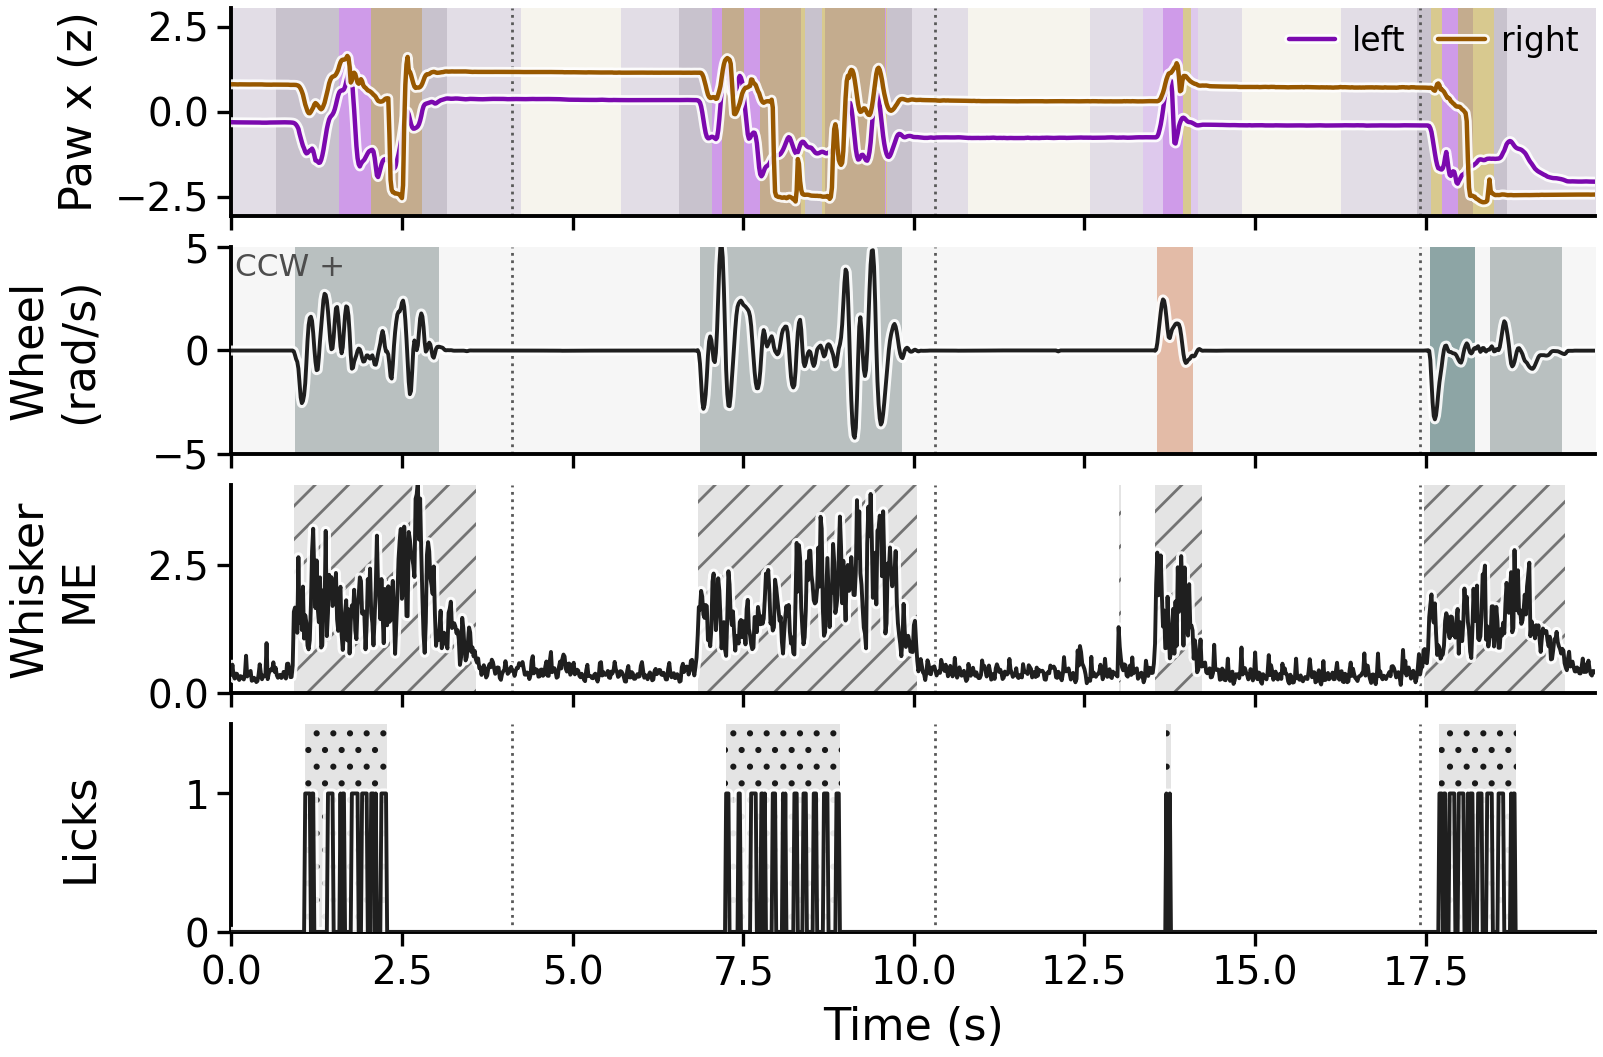

In [11]:
_d = pd.read_parquet(WHEEL_STATES_FILES_DIR + f'8_states_file_{SNIP_SESSION}_{SNIP_MOUSE}',
                     columns=['Bin', 'Lick count', 'whisker_me', 'avg_wheel_vel', 'l_paw_x', 'r_paw_x', 'most_likely_states',
                              'wheel_states', 'goCueTrigger_times'])
_bins = _d['Bin'].to_numpy(float)
_zs = lambda v: (v - np.nanmean(v)) / np.nanstd(v)
_lt, _rt = _zs(_d['l_paw_x'].to_numpy(float)), _zs(_d['r_paw_x'].to_numpy(float))
_paw, _wh, _li = ps.decode_syllables(ps.paw_codes(_d['most_likely_states'].to_numpy(float)), N_STATES)
_t0 = int(np.searchsorted(_bins, _bins[0] + TRISTRIP_START))
SL = slice(_t0, _t0 + int(TRISTRIP_SECONDS * FS))
TT = _bins[SL] - _bins[_t0]
GO = [g - _bins[_t0] for g in np.unique(_d['goCueTrigger_times'].to_numpy(float)[SL]) if np.isfinite(g)]
HALO = [pe.Stroke(linewidth=1.8, foreground='white', alpha=0.9), pe.Normal()]

def _limits(v, symmetric=False):
    f = np.asarray(v, float); f = f[np.isfinite(f)]
    lo, hi = np.nanpercentile(f, [0.5, 99.5]); pad = 0.12 * (hi - lo if hi > lo else 1.0)
    if symmetric:
        m = max(abs(lo), abs(hi)) + pad; return -m, m
    return float(min(0, lo) - pad * (lo < 0)), float(hi + pad)

def draw_F(fig, spec):
    g = spec.subgridspec(4, 1, hspace=0.15)
    chans = [('Paw x (z)', None, ListedColormap(ps.PAW_STATE_COLORS), _paw[SL], -0.5, N_STATES - 0.5),
             ('Wheel\n(rad/s)', _d['avg_wheel_vel'].to_numpy(float)[SL], ListedColormap(WSET_COLORS), _d['wheel_states'].to_numpy(float)[SL], -0.5, N_WHEEL - 0.5),
             ('Whisker\nME', _d['whisker_me'].to_numpy(float)[SL], ListedColormap(WHISK_COLORS), _wh[SL], -0.5, 1.5),
             ('Licks', _d['Lick count'].to_numpy(float)[SL], ListedColormap(LICK_COLORS), _li[SL], -0.5, 1.5)]
    axes = []
    for i, (ylab, trace, cmap, states, vmin, vmax) in enumerate(chans):
        ax = fig.add_subplot(g[i], sharex=axes[0] if axes else None); axes.append(ax)
        lo, hi = (_limits(np.r_[_lt[SL], _rt[SL]], symmetric=True) if trace is None else
                  _limits(trace, symmetric=True) if i == 1 else _limits(trace))
        if i == 3:                               # licks: headroom above the lick ticks so the dot texture shows
            hi = 1.5
        if i < 2:
            ax.imshow(np.ma.masked_invalid(states)[None, :], aspect='auto', cmap=cmap, vmin=vmin, vmax=vmax,
                      interpolation='nearest', extent=[TT[0], TT[-1], lo, hi], alpha=STATE_ALPHA, zorder=0)
        else:                                    # whisking / licking: their texture, not a grey
            edges = np.r_[TT, TT[-1] + 1 / FS]
            hatch_runs(ax, edges, states, lo, hi, (WHISK_HATCH if i == 2 else LICK_HATCH) * 2,
                       ink='0.45' if i == 2 else '0.1', zorder=0)   # lick dots dark: they are small
        for gc in GO:
            ax.axvline(gc, color='0.35', lw=0.5, ls=':', zorder=1)
        if trace is None:
            ax.plot(TT, _lt[SL], color=ps.PAW_LEFT, lw=0.8, zorder=3, label='left', path_effects=HALO)
            ax.plot(TT, _rt[SL], color=ps.PAW_RIGHT, lw=0.8, zorder=3, label='right', path_effects=HALO)
            ax.legend(frameon=False, ncol=2, loc='upper right', borderaxespad=0.1,
                      fontsize=plt.rcParams['legend.fontsize'] * 0.85)
        else:
            ax.plot(TT, trace, color='0.12', lw=0.7, zorder=3, path_effects=HALO)   
        ax.set_ylim(lo, hi); ax.set_ylabel(ylab)
        if i == 1:                               # sign convention, inside the axis (no room for a 3-line label)
            ax.text(0.003, 0.97, 'CCW +', transform=ax.transAxes, ha='left', va='top', color='0.3',
                    fontsize=plt.rcParams['font.size'] * 0.7, zorder=4)
        if i == 3:
            ax.set_yticks([0, 1])
        if i < 3:
            ax.tick_params(labelbottom=False)
    axes[-1].set_xlabel('Time (s)'); axes[-1].set_xlim(TT[0], TT[-1])
    fig.align_ylabels(axes)
    return axes

fig = plt.figure(figsize=(4.4, 3.0)); draw_F(fig, fig.add_gridspec(1, 1)[0]); plt.show()

## Panel i — occupancy per trial epoch: wheel, paw, whisk / lick

Session is the unit (each session's occupancy per epoch, then the mean over sessions). Wheel and paw are stacked partitions (wheel: light grey = still, then the 8-state set); whisking and licking are independent binary channels.

                 paw0   paw1   paw2   paw3   paw4   paw5   paw6   paw7  whisk  \
Pre-quiescence  0.221  0.517  0.087  0.050  0.068  0.033  0.019  0.006  0.500   
Quiescence      0.171  0.631  0.054  0.009  0.124  0.003  0.003  0.005  0.284   
Choice          0.102  0.152  0.224  0.177  0.136  0.133  0.070  0.006  0.699   
ITI             0.112  0.318  0.158  0.115  0.131  0.095  0.065  0.007  0.851   

                 lick  wheel0  wheel1  wheel2  wheel3  wheel4  wheel5  wheel6  \
Pre-quiescence  0.080   0.695   0.025   0.027   0.042   0.023   0.110   0.032   
Quiescence      0.041   0.986   0.002   0.001   0.002   0.001   0.006   0.001   
Choice          0.174   0.429   0.003   0.039   0.115   0.022   0.235   0.054   
ITI             0.483   0.361   0.011   0.020   0.128   0.017   0.311   0.031   

                wheel7  
Pre-quiescence   0.045  
Quiescence       0.002  
Choice           0.102  
ITI              0.122  


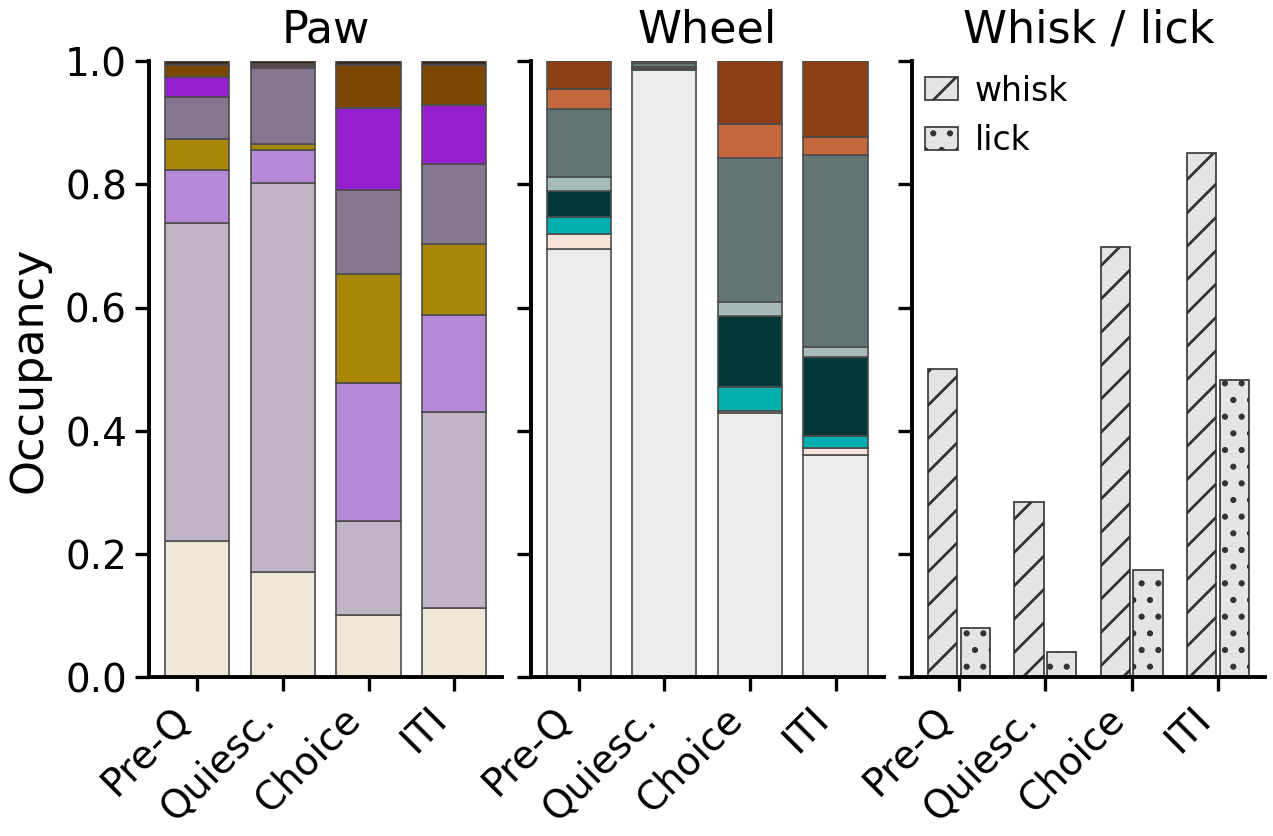

In [12]:
def occupancy_by(keys, mask):
    p, w, l, k = _paw_all[mask], _whisk_all[mask], _lick_all[mask], np.asarray(keys)[mask]
    wh = _wheel_all[mask]
    rows, names = [], []
    for kv in pd.unique(k):
        m = k == kv
        pv, wv, lv, hv = p[m].ravel(), w[m].ravel(), l[m].ravel(), wh[m].ravel()
        ok, okh = ~np.isnan(pv), ~np.isnan(hv)
        if ok.sum():
            rows.append(np.r_[np.bincount(pv[ok].astype(int), minlength=N_STATES) / ok.sum(), np.nanmean(wv), np.nanmean(lv),
                              np.bincount(hv[okh].astype(int), minlength=N_WHEEL) / max(okh.sum(), 1)])
            names.append(kv)
    return pd.DataFrame(rows, index=names, columns=[f'paw{i}' for i in range(N_STATES)] + ['whisk', 'lick'] + [f'wheel{i}' for i in range(N_WHEEL)])

OCC_EPOCH = {ep: occupancy_by(_session, _epoch == ep) for ep in EPOCHS}
OCC_EPOCH_MEAN = pd.DataFrame({ep: v.mean() for ep, v in OCC_EPOCH.items()}).T
print(OCC_EPOCH_MEAN.round(3))

def draw_G(fig, spec):
    g = spec.subgridspec(1, 3, wspace=0.08)
    ax1, axw, ax2 = fig.add_subplot(g[0]), fig.add_subplot(g[1]), fig.add_subplot(g[2])   # paw, wheel, whisk / lick
    x = np.arange(len(EPOCHS)); bottom = np.zeros(len(EPOCHS))
    for s in ORDER:
        v = OCC_EPOCH_MEAN[f'paw{s}'].to_numpy()
        ax1.bar(x, v, bottom=bottom, color=ps.PAW_STATE_COLORS[s], edgecolor='0.3', lw=0.3, width=0.75); bottom += v
    ax1.set_ylim(0, 1); ax1.set_title('Paw', fontsize=plt.rcParams['font.size']); ax1.set_ylabel('Occupancy')
    bottom = np.zeros(len(EPOCHS))
    for s in range(N_WHEEL):
        v = OCC_EPOCH_MEAN[f'wheel{s}'].to_numpy()
        axw.bar(x, v, bottom=bottom, color=WSET_COLORS[s], edgecolor='0.3', lw=0.3, width=0.75); bottom += v
    axw.set_ylim(0, 1); axw.set_title('Wheel', fontsize=plt.rcParams['font.size']); axw.tick_params(labelleft=False)
    for j, (ch, col) in enumerate([('whisk', WHISK_COLORS[1]), ('lick', '#2F3030')]):
        for e, ep in enumerate(EPOCHS):
            v = OCC_EPOCH[ep][ch].to_numpy(); xx = e + (j - 0.5) * 0.38
            ax2.bar(xx, np.nanmean(v), width=0.34, facecolor=WL_BG, edgecolor=HATCH_INK, lw=0.3,
                    hatch=(WHISK_HATCH if ch == 'whisk' else LICK_HATCH) * 2, label=ch if e == 0 else None)
    ax2.set_ylim(0, 1); ax2.set_title('Whisk / lick', fontsize=plt.rcParams['font.size'])
    ax2.tick_params(labelleft=False)          # same 0-1 scale as the paw panel
    ax2.legend(frameon=False, loc='upper left', fontsize=plt.rcParams['legend.fontsize'] * 0.85, handlelength=1, borderaxespad=0)
    for ax in (ax1, axw, ax2):
        ax.set_xticks(x); ax.set_xticklabels(ps.EPOCH_SHORT, rotation=45, ha='right')
    return [ax1, axw, ax2]

fig = plt.figure(figsize=(3.6, 2.0)); draw_G(fig, fig.add_gridspec(1, 1)[0]); plt.show()

## Panels k, l — conditional syllable donuts, wheel innermost

Four nested rings, each conditioned on everything inside it, wheel first: P(wheel state) (the 8 states; light grey = still), P(paw | wheel), P(whisk | wheel, paw) (grey = whisking), P(lick | wheel, paw, whisk) (dark grey = licking). Every wedge's angle is the joint probability; probabilities within trial, averaged over trials. Example sessions as in the paw figure.

  CSH_ZAD_029      fece187f   1523 trials  0.0% missing bins
  NR_0027          0f77ca5d   1186 trials  0.0% missing bins
  ibl_witten_29    af55d16f   1116 trials  0.0% missing bins
  ibl_witten_26    dc21e80d   1101 trials  0.0% missing bins


all trials: P(paw) = [0.154 0.404 0.134 0.092 0.11  0.064 0.036 0.006]


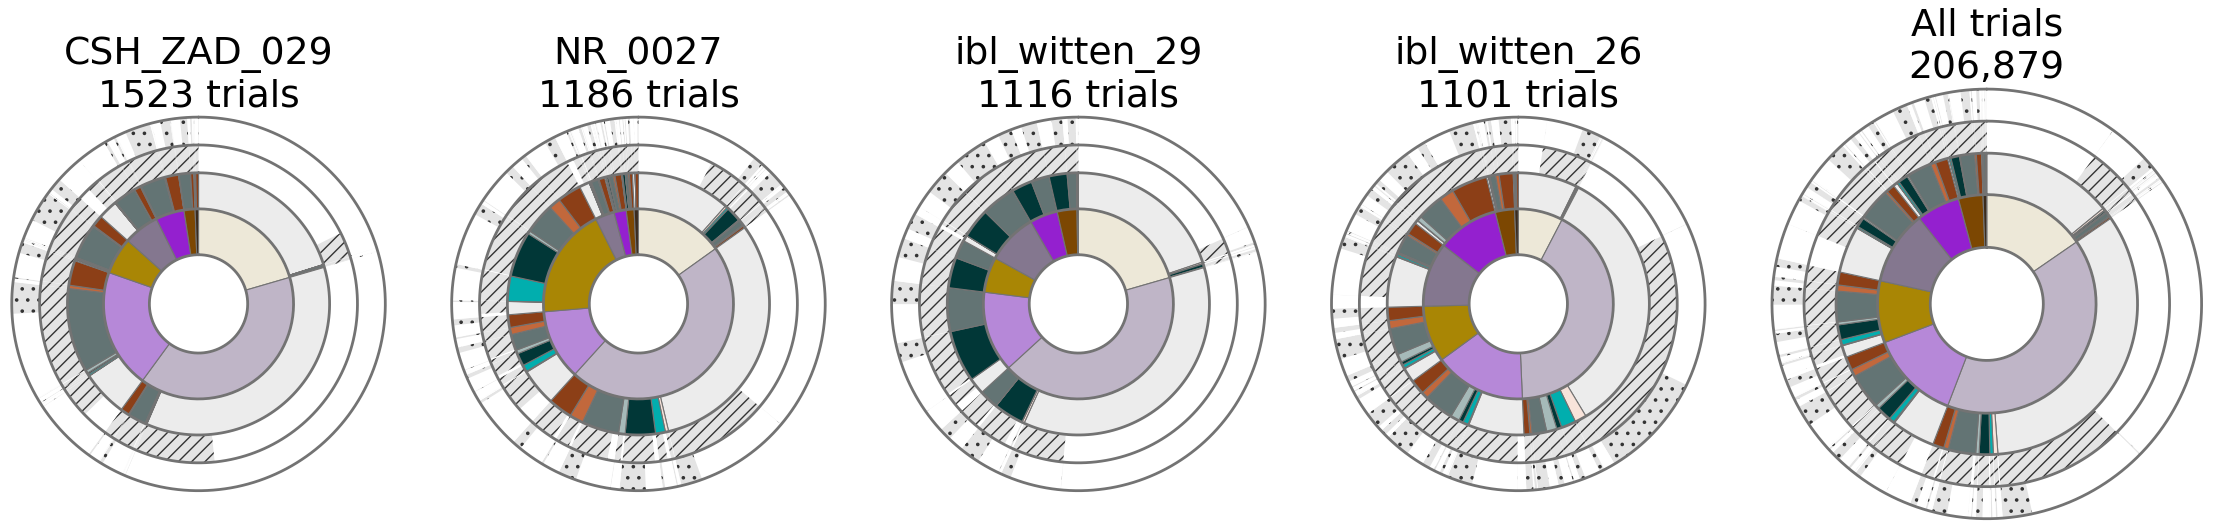

In [13]:
_missing = pd.Series(np.isnan(_arr).mean(axis=1), index=_session).groupby(level=0).mean()
EXAMPLES = list(seq.groupby(['session', 'mouse_name']).size().div(len(EPOCHS)).reset_index(name='n_trials')
                .assign(missing=lambda d: d['session'].map(_missing)).query('missing <= @MAX_MISSING')
                .sort_values('n_trials', ascending=False).drop_duplicates('mouse_name')
                .head(N_EXAMPLES).itertuples(index=False, name=None))
for s, m, n, miss in EXAMPLES:
    print(f'  {m:16s} {s[:8]}  {int(n):5d} trials  {miss:.1%} missing bins')

def conditional_probs(codes, wheel):
    """Per trial, then averaged: P(paw), P(wheel | paw), P(whisk | paw, wheel), P(lick | paw, wheel, whisk)."""
    import warnings
    paw, whisk, lick = ps.decode_syllables(np.asarray(codes, float), N_STATES)
    wheel = np.asarray(wheel, float)
    n_tr = paw.shape[0]
    fp = np.full((n_tr, N_STATES), np.nan); fh = np.full((n_tr, N_STATES, N_WHEEL), np.nan)
    fw = np.full((n_tr, N_STATES, N_WHEEL, 2), np.nan); fl_ = np.full((n_tr, N_STATES, N_WHEEL, 2, 2), np.nan)
    for t in range(n_tr):
        ok = ~np.isnan(paw[t]) & ~np.isnan(wheel[t])
        if not ok.sum():
            continue
        pv, hv = paw[t][ok].astype(int), wheel[t][ok].astype(int)
        wv, lv = whisk[t][ok].astype(int), lick[t][ok].astype(int)
        fp[t] = np.bincount(pv, minlength=N_STATES) / len(pv)
        for s in np.unique(pv):
            ms = pv == s
            fh[t, s] = np.bincount(hv[ms], minlength=N_WHEEL) / ms.sum()
            for h in np.unique(hv[ms]):
                mh = ms & (hv == h)
                for w in (0, 1):
                    mw = mh & (wv == w)
                    fw[t, s, h, w] = mw.sum() / mh.sum()
                    if mw.sum():
                        for l in (0, 1):
                            fl_[t, s, h, w, l] = (mw & (lv == l)).sum() / mw.sum()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        P = np.nanmean(fp, axis=0)
        return P / np.nansum(P), np.nanmean(fh, axis=0), np.nanmean(fw, axis=0), np.nanmean(fl_, axis=0)

DONUT = {s: conditional_probs(codes_for(seq[seq['session'] == s]), codes_for(seq[seq['session'] == s], 'wheel_binned_sequence'))
         for s, *_ in EXAMPLES}
DONUT['all'] = conditional_probs(ALL_CODES, ALL_WHEEL)
print('all trials: P(paw) =', np.round(DONUT['all'][0], 3))

def draw_donut(fig, spec, key, title):
    ax = fig.add_subplot(spec, projection='polar')
    P_p, P_h, P_w, P_l = DONUT[key]                # paw, wheel | paw, whisk | paw, wheel, lick | paw, wheel, whisk
    radii = [(0.30, 0.58), (0.58, 0.80), (0.80, 0.97), (0.97, 1.14)]
    # make the polar axes exactly square and sit it at the bottom of its cell, so the title hugs the donut
    pos, (fw_, fh_) = ax.get_position(), fig.get_size_inches()
    side = min(pos.width * fw_, pos.height * fh_)
    ax.set_position([pos.x0 + (pos.width - side / fw_) / 2, pos.y0, side / fw_, side / fh_])
    ax.set_theta_offset(np.pi / 2); ax.set_theta_direction(-1); ax.set_axis_off()
    def wedge(start, th, ring, color, hatch=''):
        ax.bar(start + th / 2, radii[ring][1] - radii[ring][0], width=th, bottom=radii[ring][0],
               color=color, edgecolor='0.45', linewidth=0.2 if ring < 2 else 0)   # whisk / lick rings: no wedge edges, textures run on
        if hatch:                                # texture on top, in its own ink (the hatch takes the edge colour)
            ax.bar(start + th / 2, radii[ring][1] - radii[ring][0], width=th, bottom=radii[ring][0],
                   fill=False, edgecolor=HATCH_INK, linewidth=0, hatch=hatch, hatch_linewidth=0.25)
    for ring in range(4):
        start = 0.0
        for p in range(N_STATES):
            if ring == 0:
                parts = [(P_p[p], ps.PAW_STATE_COLORS[p], '')]
            elif ring == 1:
                parts = [(P_p[p] * P_h[p, h], WSET_COLORS[h], '') for h in range(N_WHEEL)]
            elif ring == 2:
                parts = [(P_p[p] * P_h[p, h] * P_w[p, h, w], WL_BG if w else 'white', WHISK_HATCH * 5 if w else '')   # fine and dense: the rings are thin
                         for h in range(N_WHEEL) for w in (0, 1)]
            else:
                parts = [(P_p[p] * P_h[p, h] * P_w[p, h, w] * P_l[p, h, w, l], WL_BG if l else 'white', LICK_HATCH * 3 if l else '')
                         for h in range(N_WHEEL) for w in (0, 1) for l in (0, 1)]
            for frac_, col, hat in parts:
                th = 2 * np.pi * frac_
                if np.isfinite(th) and th > 0:
                    wedge(start, th, ring, col, hat); start += th
    tr = np.linspace(0, 2 * np.pi, 200)
    for r in [radii[0][0], *[rr[1] for rr in radii]]:
        ax.plot(tr, [r] * len(tr), color='0.45', lw=0.5)
    ax.set_ylim(0, radii[3][1] * 1.02)
    ax.text(0.5, 1.0, title, transform=ax.transAxes, ha='center', va='bottom', fontsize=plt.rcParams['font.size'] * 0.85)
    return [ax]

def draw_HJM(fig, spec, stack_ratio=1.45):
    """Donuts on top; under each example donut its trial stack, under the all-trials donut the time-warped composition."""
    n = len(EXAMPLES)
    g = spec.subgridspec(3, n + 1, height_ratios=[0.1, 1, stack_ratio], width_ratios=[1] * n + [1.15],
                         wspace=0.15, hspace=0.12)
    out = {'H': [], 'J': [], 'M': [], 'K': []}
    for j, (s, m, ntr, _) in enumerate(EXAMPLES):
        out['H'] += draw_donut(fig, g[1, j], s, f'{m}\n{int(ntr)} trials')
        out['M'] += draw_stack(fig.add_subplot(g[2, j]), s, m, row_labels=(j == 0))
    out['J'] += draw_donut(fig, g[1, n], 'all', f"All trials\n{len(ALL_CODES):,}")
    out['K'] += draw_comp(fig.add_subplot(g[2, n]))
    out['M'][0].set_xlabel('Time from go cue (s)')
    return out

def draw_HJ(fig, spec):
    n = len(EXAMPLES)
    spec = spec.subgridspec(2, 1, height_ratios=[0.15, 1], hspace=0)[1]   # top strip = room for the donut titles
    g = spec.subgridspec(1, n + 1, width_ratios=[1] * n + [1.15], wspace=0.15)
    out = {'H': [], 'J': []}
    for j, (s, m, ntr, _) in enumerate(EXAMPLES):
        out['H'] += draw_donut(fig, g[j], s, f'{m}\n{int(ntr)} trials')
    out['J'] += draw_donut(fig, g[n], 'all', f"All trials\n{len(ALL_CODES):,}")
    return out

fig = plt.figure(figsize=(7.09, 1.9)); draw_HJ(fig, fig.add_gridspec(1, 1)[0]); plt.show()

## Panel m — trial stacks: wheel, paw, whisking and licking as four rows per trial

The same example sessions as the donuts, `N_STACK_TRIALS` consecutive trials each, aligned to the go cue (frame resolution, 60 Hz). Every trial is four rows (wheel, paw, whisking, licking) followed by a blank gap, so trials stand apart. Ticks: stimulus on (black) and feedback (green = correct, red = error).

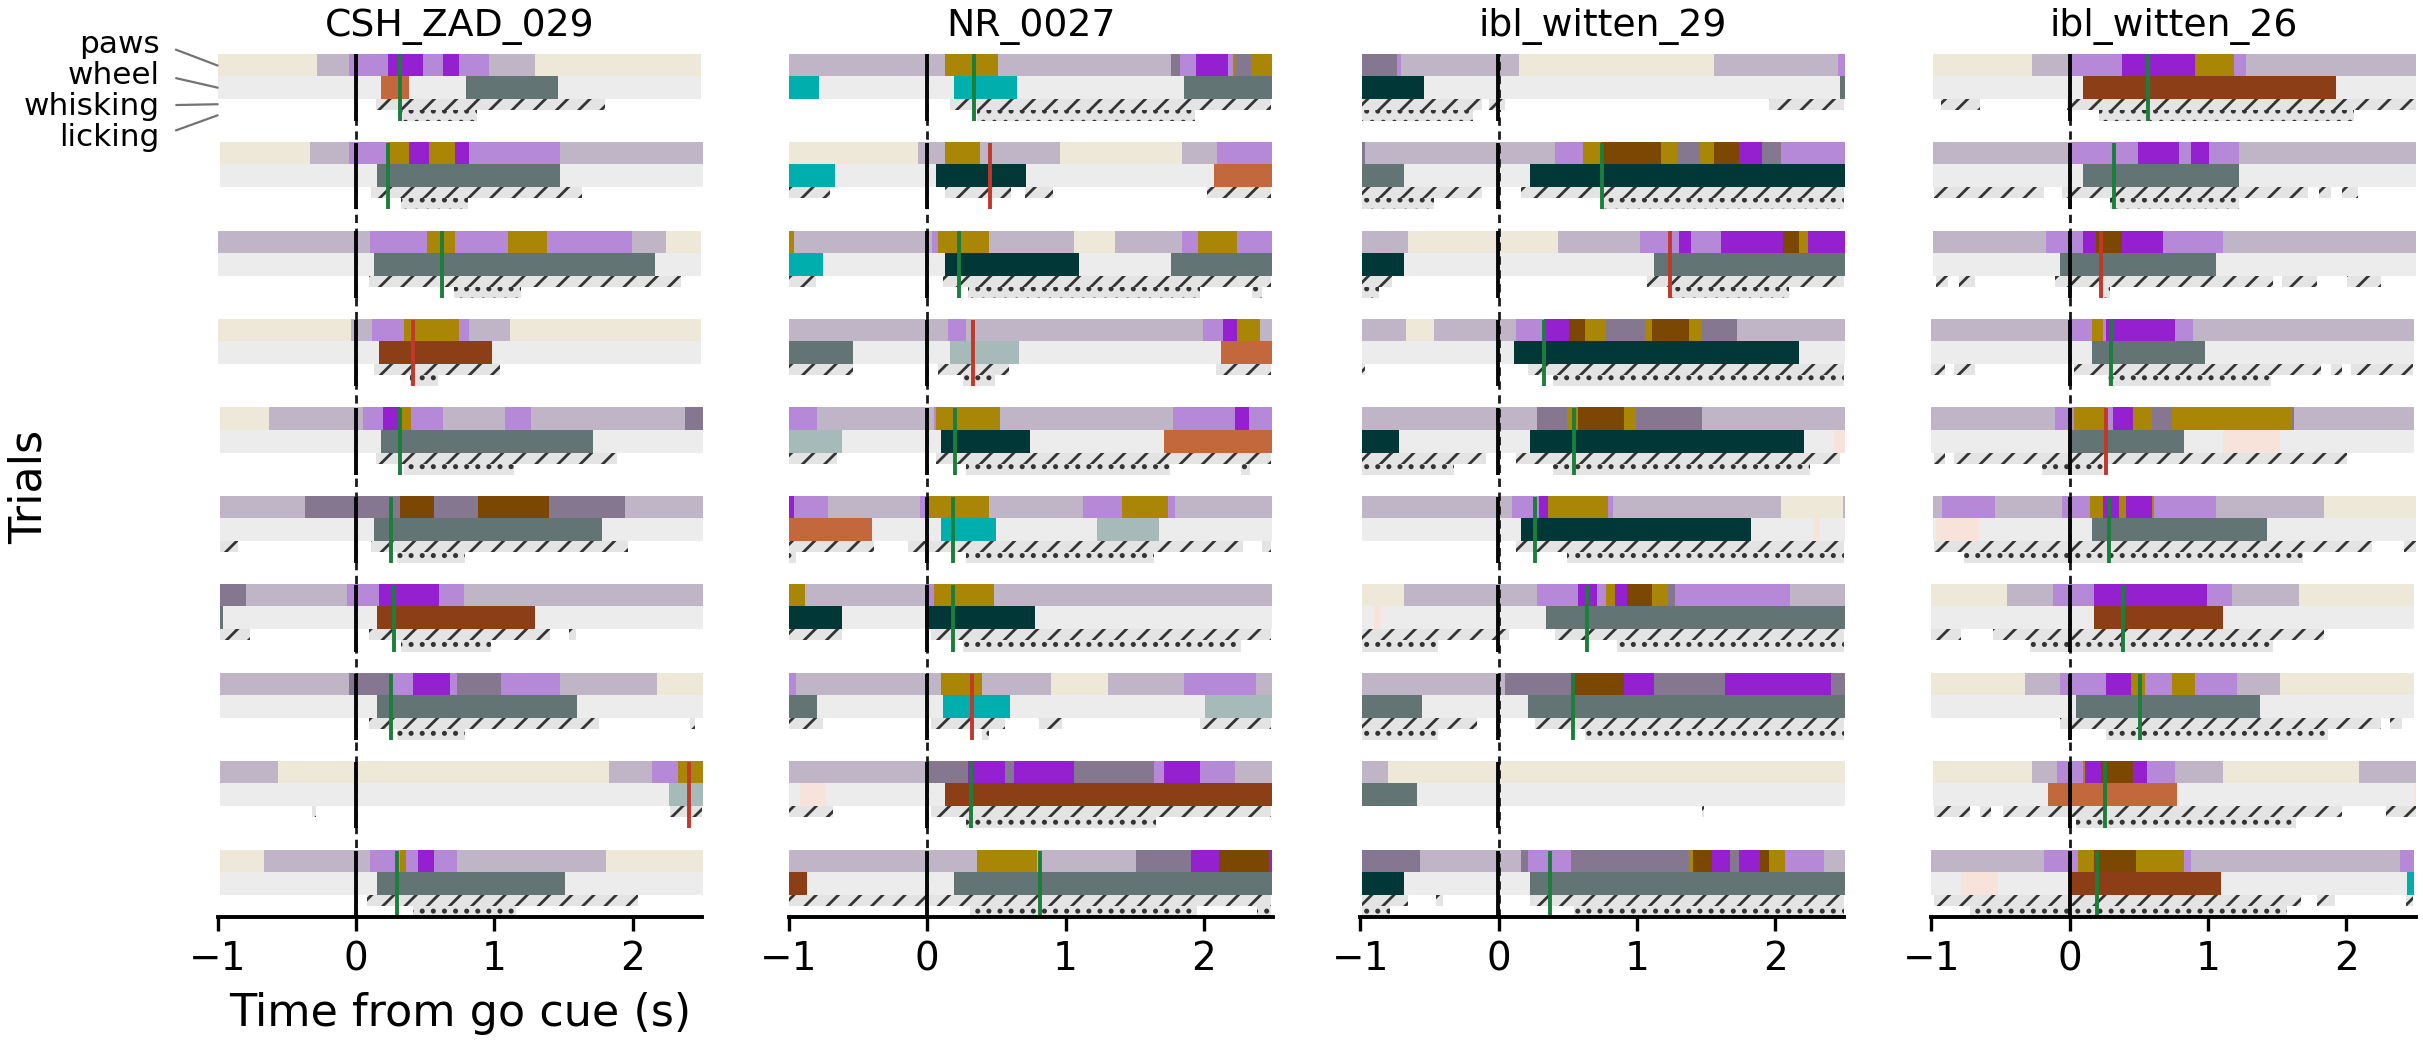

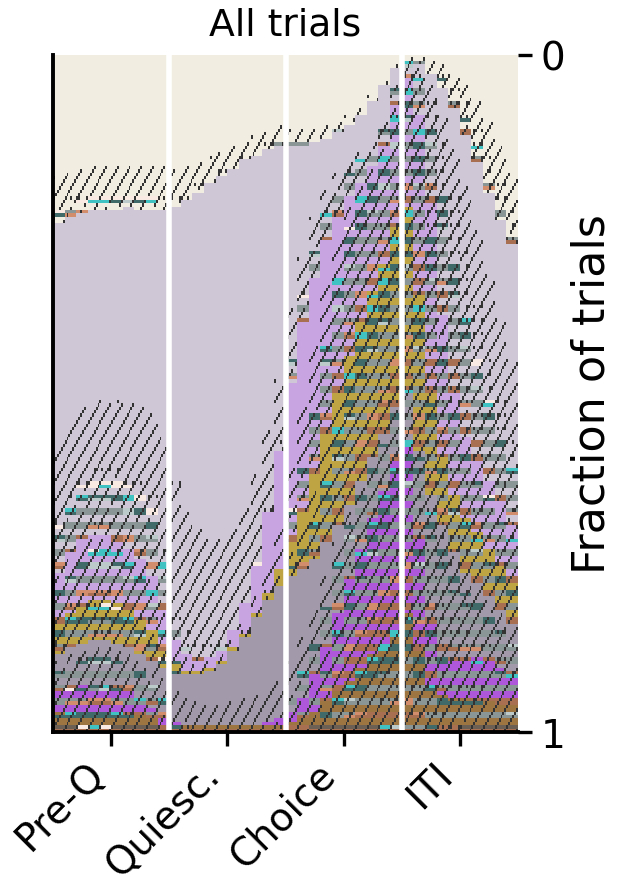

In [14]:
N_STACK_TRIALS = 10
STACK_ROWS = [('paw', 3), ('wheel', 3), ('whisk', 1.5), ('lick', 1.5)]   # (channel, height) per trial
STACK_GAP = 3.0                                                           # blank space between trials
STACK_H = sum(h for _, h in STACK_ROWS) + STACK_GAP
_PAW_RGB = np.array([to_rgb(c) for c in ps.PAW_STATE_COLORS])
_WHEEL_RGB = np.array([to_rgb(c) for c in WSET_COLORS])
_WL_RGB = {'whisk': np.array(to_rgb(WHISK_COLORS[1])), 'lick': np.array(to_rgb(LICK_COLORS[1]))}

def trial_stack(session, mouse, dt=1 / FS):
    """paw, wheel, whisk, lick (trials x frames) around the go cue, and the trials table."""
    st = pd.read_parquet(f'{WHEEL_STATES_FILES_DIR}{N_STATES}_states_file_{session}_{mouse}',
                         columns=['Bin', 'most_likely_states', 'wheel_states'])
    tr = (pd.read_parquet(f'{TRIALS_DIR}session_trials_{session}_{mouse}').reset_index(drop=True)
          .iloc[TRIAL_START:TRIAL_START + N_STACK_TRIALS])
    bins = st['Bin'].to_numpy(float)
    code, wheel = ps.paw_codes(st['most_likely_states'].to_numpy(float)), st['wheel_states'].to_numpy(float)
    grid = np.arange(-TIME_BEFORE, TIME_AFTER + dt / 2, dt)
    C = np.full((len(tr), len(grid)), np.nan); W = C.copy()
    for i, a in enumerate(tr[ALIGN_TO].to_numpy(float)):
        if not np.isfinite(a):
            continue
        lo, hi = np.searchsorted(bins, [a - TIME_BEFORE, a + TIME_AFTER])
        idx = np.round((bins[lo:hi] - a + TIME_BEFORE) / dt).astype(int)
        k = (idx >= 0) & (idx < len(grid))
        C[i, idx[k]], W[i, idx[k]] = code[lo:hi][k], wheel[lo:hi][k]
    paw, whisk, lick = ps.decode_syllables(C, N_STATES)
    return paw, W, whisk, lick, tr

def draw_stack(ax, session, mouse, row_labels=False, title=False):
    paw, W, whisk, lick, tr = trial_stack(session, mouse)
    rgb = lambda v, lut: np.where(np.isfinite(v)[:, None], lut[np.nan_to_num(v).astype(int)], 1.0)
    ext = [-TIME_BEFORE, TIME_AFTER]
    for i, (_, row) in enumerate(tr.iterrows()):
        y = i * STACK_H
        for ch, h in STACK_ROWS:
            if ch == 'paw':
                img = rgb(paw[i], _PAW_RGB)
            elif ch == 'wheel':
                img = rgb(W[i], _WHEEL_RGB)
            else:                                # whisking / licking: texture on white
                img = None
                v = (whisk if ch == 'whisk' else lick)[i]
                edges = np.linspace(*ext, len(v) + 1)
                hatch_runs(ax, edges, v, y, y + h, (WHISK_HATCH if ch == 'whisk' else LICK_HATCH) * 3, zorder=2)
            if img is not None:
                ax.imshow(img[None], aspect='auto', interpolation='nearest', extent=[*ext, y + h, y])
            y += h
        a = row[ALIGN_TO]
        def mark(t, c):
            if np.isfinite(t) and -TIME_BEFORE <= t - a <= TIME_AFTER:
                ax.plot([t - a] * 2, [i * STACK_H, i * STACK_H + STACK_H - STACK_GAP], color=c, lw=0.7, solid_capstyle='butt')
        mark(row.get('stimOn_times', np.nan), EVENT_COLORS['stim on'])
        fb = row.get('feedbackType', np.nan)
        if np.isfinite(fb):
            mark(row.get('feedback_times', np.nan), FEEDBACK_COLORS.get(int(fb), '0.4'))
    ax.axvline(0, color='0.1', lw=0.5, ls=(0, (3, 2)), zorder=0)
    ax.set_xlim(*ext); ax.set_ylim(len(tr) * STACK_H - STACK_GAP, 0)
    ax.set_yticks([]); ax.spines['left'].set_visible(False)
    if row_labels:                               # name the rows of the first trial, fanned out with leader lines
        y, fs_ = 0.0, plt.rcParams['font.size'] * 0.7
        for k, (ch, h) in enumerate(STACK_ROWS):
            ax.annotate({'wheel': 'wheel', 'paw': 'paws', 'whisk': 'whisking', 'lick': 'licking'}[ch],
                        xy=(ext[0], y + h / 2), xytext=(ext[0] - 0.42, -1.5 + k * 4.2), ha='right', va='center',
                        fontsize=fs_, annotation_clip=False,
                        arrowprops=dict(arrowstyle='-', color='0.45', lw=0.4, shrinkA=1, shrinkB=0, relpos=(1, 0.5)))
            y += h
        ax.set_ylabel('Trials', labelpad=30)
    if title:
        ax.set_title(mouse, fontsize=plt.rcParams['font.size'] * 0.85)
    return [ax]

def draw_M(fig, spec):
    g = spec.subgridspec(1, len(EXAMPLES), wspace=0.18)
    axes = []
    for j, (s, m, *_ ) in enumerate(EXAMPLES):
        axes += draw_stack(fig.add_subplot(g[j]), s, m, row_labels=(j == 0), title=True)
    axes[0].set_xlabel('Time from go cue (s)')
    return axes

fig = plt.figure(figsize=(7.09, 2.8)); draw_M(fig, fig.add_gridspec(1, 1)[0]); plt.show()

# ---- the time-warped composition over all trials, textured like the syllables
COMP_ROWS, COMP_COL_UP = 200, 6          # pixel rows (trials resampled) and pixels per bin
COMP_STRIPE, COMP_WHISK, COMP_DOT = 4, 6, 4
COMP_ALPHA = 0.75                         # paw / wheel colours washed toward white so the textures read
_INK_RGB = np.array(to_rgb(HATCH_INK))
_wash = lambda rgb: 1 - COMP_ALPHA * (1 - rgb)
_PAW_RANK = np.argsort(list(ps.PAW_VIGOR_ORDER))        # paw state -> rank in vigor order

def composition_image(codes, wheel):
    """For every bin, the trials sorted by (paw state in vigor order, wheel, whisking, licking) and resampled to
    COMP_ROWS rows: each column is that bin's joint composition. Returns paw, wheel, whisk, lick pixel arrays."""
    paw, wh, li = ps.decode_syllables(np.asarray(codes, float), N_STATES)
    out = {k: np.full((COMP_ROWS, codes.shape[1]), np.nan) for k in ('paw', 'wheel', 'whisk', 'lick')}
    for b in range(codes.shape[1]):
        ok = np.isfinite(paw[:, b]) & np.isfinite(wheel[:, b])
        if not ok.any():
            continue
        p, w, h, l = paw[ok, b], wheel[ok, b], wh[ok, b], li[ok, b]
        key = np.lexsort((l, h, w, _PAW_RANK[p.astype(int)]))
        pick = key[np.linspace(0, len(key) - 1, COMP_ROWS).round().astype(int)]
        for k, v in (('paw', p), ('wheel', w), ('whisk', h), ('lick', l)):
            out[k][:, b] = v[pick]
    return {k: np.repeat(v, COMP_COL_UP, axis=1) for k, v in out.items()}

def texture_rgb(pr, wr, whr, lr):
    """paw = base colour; wheel = horizontal stripes in its colour while it moves; whisking '/'; licking dots."""
    yy, xx = np.mgrid[:pr.shape[0], :pr.shape[1]]
    img = np.where(np.isfinite(pr)[..., None], _wash(_PAW_RGB)[np.nan_to_num(pr).astype(int)], 1.0)
    wheel_on = (np.nan_to_num(wr) > 0) & ((yy // (COMP_STRIPE // 2)) % 2 == 1)
    img = np.where(wheel_on[..., None], _wash(_WHEEL_RGB)[np.nan_to_num(wr).astype(int)], img)
    whisk_on = (whr == 1) & (((xx + yy) % COMP_WHISK) == 0)
    img = np.where(whisk_on[..., None], _INK_RGB, img)
    lick_on = (lr == 1) & (xx % COMP_DOT == 1) & (yy % COMP_DOT == 2)
    return np.where(lick_on[..., None], _INK_RGB, img)

COMP_ALL = composition_image(ALL_CODES, ALL_WHEEL)

def draw_comp(ax, A=None, title=None):
    A = COMP_ALL if A is None else A
    n_bins = A['paw'].shape[1] // COMP_COL_UP
    ax.imshow(texture_rgb(A['paw'], A['wheel'], A['whisk'], A['lick']), aspect='auto', interpolation='nearest',
              extent=[0, n_bins, 1, 0])
    for e in range(1, len(EPOCHS)):
        ax.axvline(e * n_bins / len(EPOCHS), color='white', lw=1.0)
    ax.set_xticks((np.arange(len(EPOCHS)) + 0.5) * n_bins / len(EPOCHS))
    ax.set_xticklabels(ps.EPOCH_SHORT, rotation=45, ha='right')
    ax.set_yticks([0, 1]); ax.set_ylabel('Fraction of trials', labelpad=1)
    ax.yaxis.set_label_position('right'); ax.yaxis.tick_right()
    if title:
        ax.set_title(title, fontsize=plt.rcParams['font.size'] * 0.85)
    return [ax]

fig, ax = plt.subplots(figsize=(1.5, 2.2)); draw_comp(ax, title='All trials'); plt.show()

## Legends

Paw states and whisk / lick hatching (as the paw figure), the 10 wheel states, and the donut rings.

In [15]:
def draw_legends(fig, spec, stacks=False):
    ax = fig.add_subplot(spec); ax.set_axis_off()
    fs = plt.rcParams['legend.fontsize'] * 0.9
    ps.paw_legend(ax, ncol=4, hatch=True, missing=False, loc='upper left', bbox_to_anchor=(0.0, 1.0), fontsize=fs,
                  title_fontsize=fs)
    ax.add_artist(ax.get_legend())
    wh = [Patch(facecolor=c, edgecolor='0.45', lw=0.3, label=n) for n, c in zip(WSET_LABELS, WSET_COLORS)]
    leg2 = ax.legend(handles=wh, ncol=3, frameon=False, loc='upper center', bbox_to_anchor=(0.6, 1.0), fontsize=fs,
                     title='Wheel states (direction · vigor)\nCW reports left, CCW reports right', title_fontsize=fs)
    ax.add_artist(leg2)
    ev = [Patch(facecolor=ps.PAW_STATE_COLORS[2], edgecolor='0.45', label='inner ring: paw'),
          Patch(facecolor=STILL_COLOR, edgecolor='0.45', label='ring 2: wheel (grey = still)'),
          Patch(facecolor=WL_BG, edgecolor=HATCH_INK, hatch=WHISK_HATCH * 3, label='ring 3: whisking'),
          Patch(facecolor=WL_BG, edgecolor=HATCH_INK, hatch=LICK_HATCH * 3, label='outer ring: licking'),
          ]
    if stacks:
        ev += [Line2D([], [], color=EVENT_COLORS['stim on'], lw=0.8, label='stack: stimulus on'),
               Line2D([], [], color=FEEDBACK_COLORS[1], lw=0.8, label='stack: correct feedback'),
               Line2D([], [], color=FEEDBACK_COLORS[-1], lw=0.8, label='stack: error feedback')]
    ax.legend(handles=ev, ncol=1, frameon=False, loc='upper right', bbox_to_anchor=(1.0, 1.0), fontsize=fs,
              title='Donut rings' + (' / stack events' if stacks else ''), title_fontsize=fs)
    return [ax]

## The assembled figures (two images)

180 mm wide each.
- **Figure 1** (`fig_segmentation_wheel_1`): a | b (cartoons); c | d | e (wheel); f | g | h (paw).
- **Figure 2** (`fig_segmentation_wheel_2`): a | b (channels, then occupancy); c (example donuts) + d (all trials); e (trial stacks, four rows per trial); legends.

Each writes `figure_generation/figures/<name>.pdf` (undated) and a dated SVG.

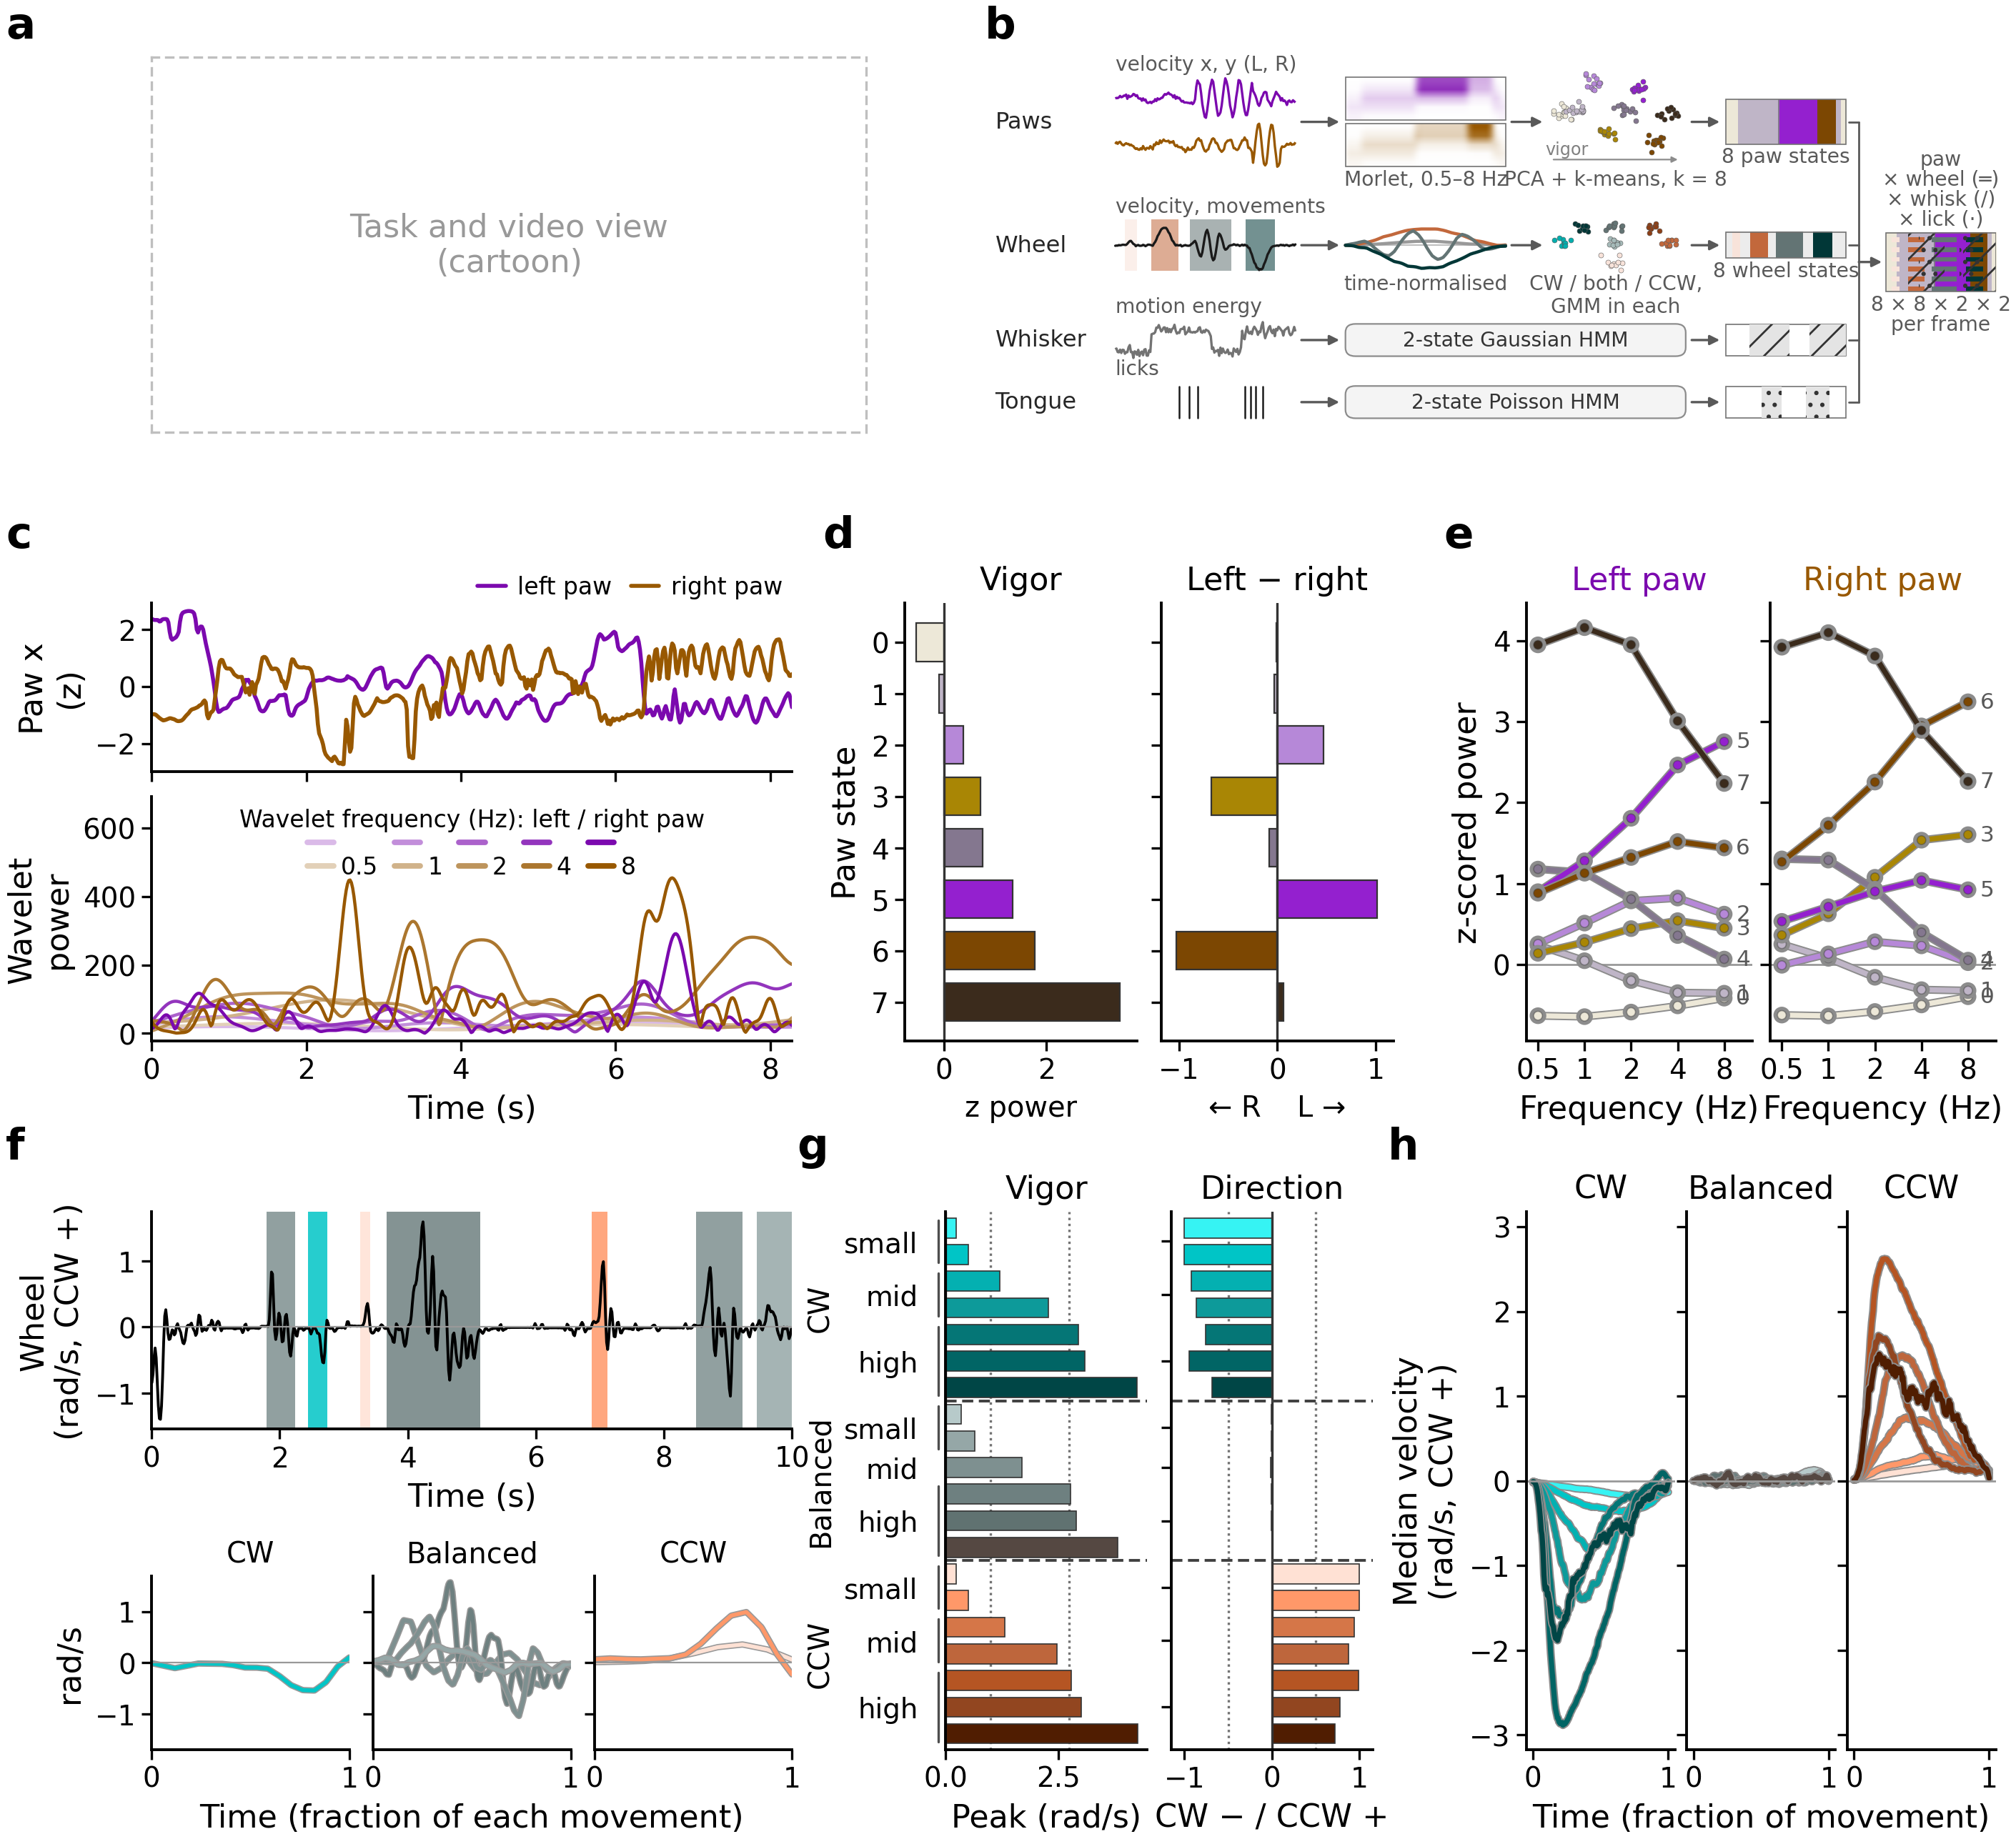

wrote figure_generation/figures/fig_segmentation_wheel_1_05-11-2026.svg


wrote figure_generation/figures/fig_segmentation_wheel_1.pdf


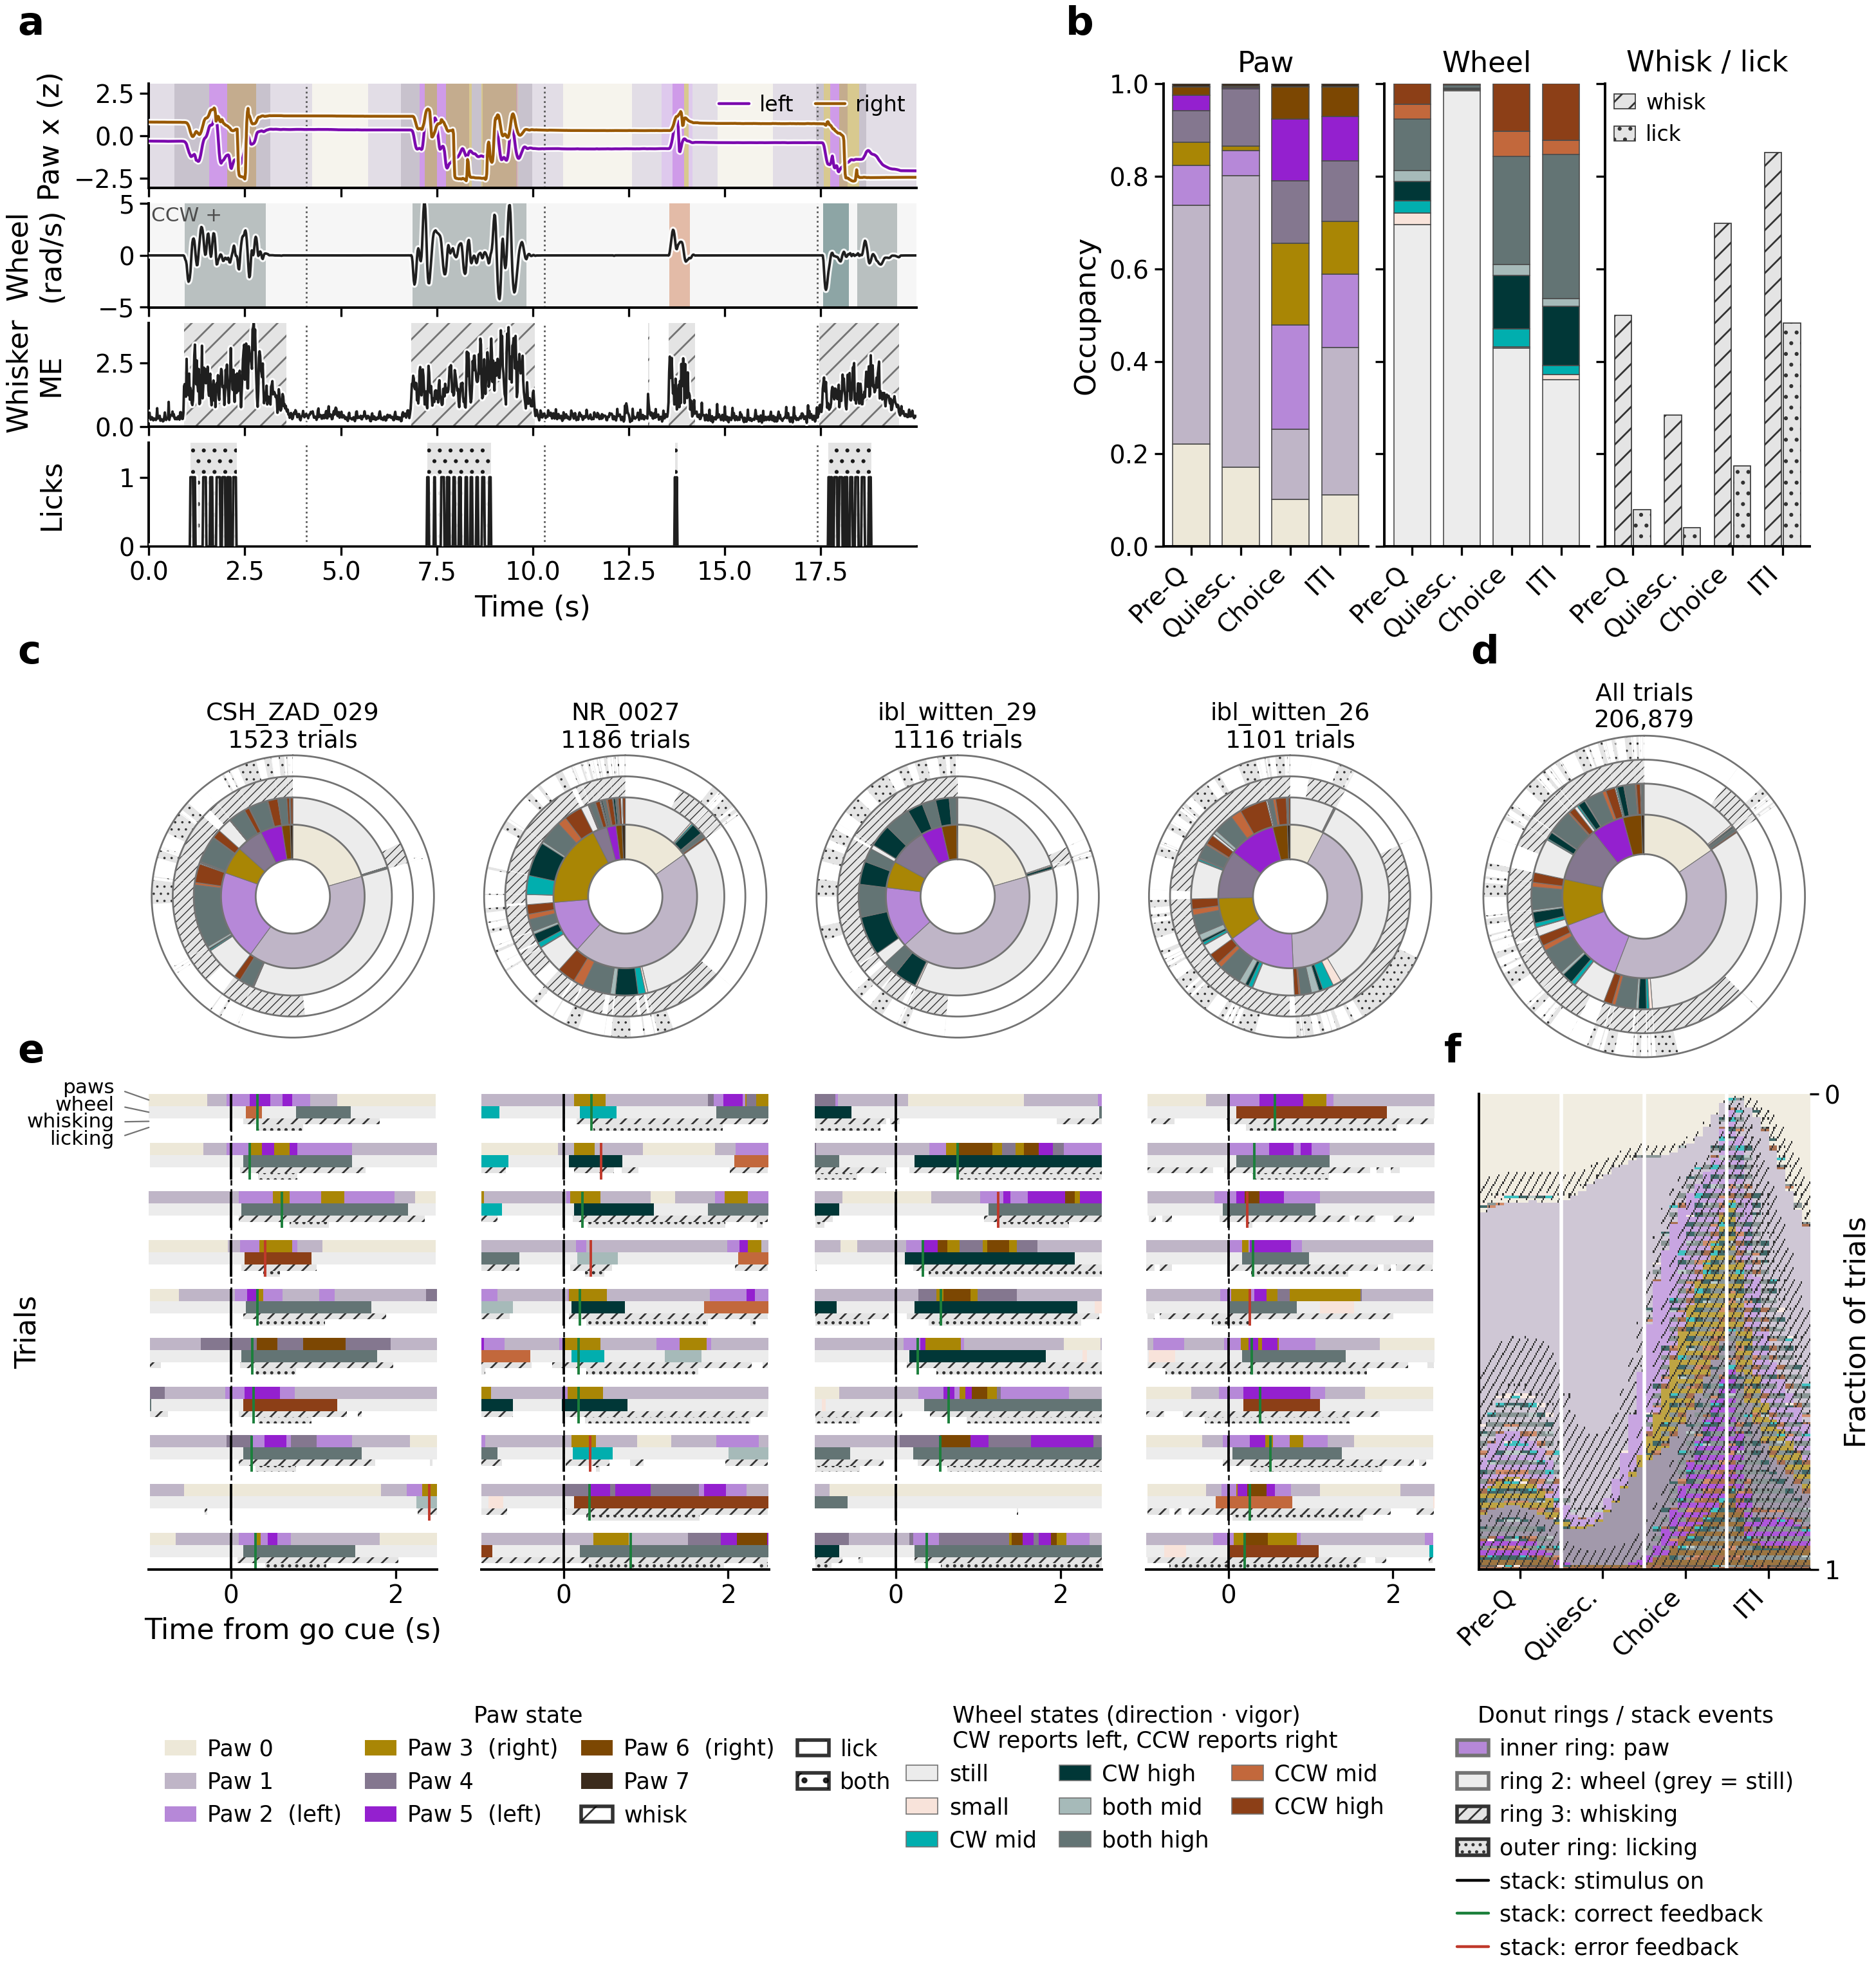

wrote figure_generation/figures/fig_segmentation_wheel_2_05-11-2026.svg


wrote figure_generation/figures/fig_segmentation_wheel_2.pdf


In [16]:
from datetime import date
import fig_layout as fl          # shared margins, left-edge alignment and panel letters (figure_generation/fig_layout.py)
OUT_DIR = PI / 'figure_generation' / 'figures'
OUT_DIR.mkdir(exist_ok=True)
def save(fig, name):
    for path in [OUT_DIR / f"{name}_{date.today().strftime('%d-%m-%Y')}.svg", OUT_DIR / f'{name}.pdf']:
        fig.savefig(path)
        print('wrote', path.relative_to(PI))

# ---------------------------------------------------------------- figure 1: cartoons, wheel row, paw row
fig = plt.figure(figsize=(fl.FIG_WIDTH, 6.3))
outer = fig.add_gridspec(3, 1, height_ratios=[1.5, 1.75, 2.15], hspace=fl.ROW_HSPACE, **fl.MARGINS)
r1 = outer[0].subgridspec(1, 2, width_ratios=[1, 1.4], wspace=0.15)
r2 = outer[1].subgridspec(1, 3, width_ratios=[3.0, 2.0, 2.2], wspace=0.3)   # paw row first
rw = outer[2].subgridspec(1, 3, width_ratios=[3.0, 2.0, 2.2], wspace=0.3)   # wheel row, under the paw row
panels = {'A': draw_A(fig, r1[0]), 'B': draw_B(fig, r1[1]),
          'W1': draw_W1(fig, rw[0]), 'W2': draw_W2(fig, rw[1]), 'W3': draw_W3(fig, rw[2]),
          'C': draw_C(fig, r2[0]), 'D': draw_D(fig, r2[1]), 'E': draw_E(fig, r2[2])}
fl.align_left(fig, panels['A'] + panels['C'] + panels['W1'][:1])   # first axis only where a panel has columns
r_ = fig.canvas.get_renderer()
fb = lambda a: a.get_tightbbox(r_).transformed(fig.transFigure.inverted())
# g moves left up to f (keeping room for its own y labels) and right up to h's y label
c_right = max(fb(a).x1 for a in panels['C'])
d0, d1 = (a.get_position() for a in panels['D'])
new_x0 = c_right + 0.02 + (d0.x0 - fb(panels['D'][0]).x0)
gap = d1.x0 - d0.x1
w = (fb(panels['E'][0]).x0 - 0.03 - new_x0 - gap) / 2
panels['D'][0].set_position([new_x0, d0.y0, w, d0.height])
panels['D'][1].set_position([new_x0 + w + gap, d1.y0, w, d1.height])
fl.place_letters(fig, panels, rows=[['A', 'B'], ['C', 'D', 'E'], ['W1', 'W2', 'W3']], left=['A', 'C', 'W1'],
                 letters={'A': 'a', 'B': 'b', 'C': 'c', 'D': 'd', 'E': 'e', 'W1': 'f', 'W2': 'g', 'W3': 'h'})
plt.show()
save(fig, f'{FIG}_1')

# ---------------------------------------------------------------- figure 2: channels, occupancy, donuts, trial stacks
fig = plt.figure(figsize=(fl.FIG_WIDTH, 7.5))
outer = fig.add_gridspec(3, 1, height_ratios=[2.1, 4.1, 0.95], hspace=fl.ROW_HSPACE * 0.6, **fl.MARGINS)
r3 = outer[0].subgridspec(1, 2, width_ratios=[3.8, 3.2], wspace=0.35)
panels = {'F': draw_F(fig, r3[0]), 'G': draw_G(fig, r3[1])}
panels.update(draw_HJM(fig, outer[1]))
draw_legends(fig, outer[2], stacks=True)
fl.place_letters(fig, panels, rows=[['F', 'G'], ['H', 'J'], ['M', 'K']], left=['F', 'H', 'M'],
                 letters={'F': 'a', 'G': 'b', 'H': 'c', 'J': 'd', 'M': 'e', 'K': 'f'})
plt.show()
save(fig, f'{FIG}_2')